In [1]:
from TableToDict import GetDFv2, GetDF, DisplayColumns
from HuRI import GetHuRI
#from ccsblib import  huri
from  Load_CCSB_Data import GetOrfMapping
import pandas as pd
import numpy as np

from matplotlib import pyplot as plt
import seaborn as sns

from PandasToMySQL import MakeSummaryTable

%matplotlib inline
%config InlineBackend.figure_format='retina'

pd.options.display.max_rows = 1200
pd.options.display.max_columns = 60

In [2]:
from glob import glob
from os import stat

In [3]:
from scipy.stats import pearsonr, spearmanr, linregress

In [4]:
from statsmodels.nonparametric.smoothers_lowess import lowess as  sm_lowess

In [5]:
from joypy import joyplot

In [6]:
from PlateDict import rev_wellMap, wellMap

A01
31


## Allele collection

In [7]:
allele_info_df = pd.read_csv('../database_management/20220228_Mikko_table_creation_and_updates/VUS_wt_allele_collection_entry_plates_allele_infos.csv', index_col=0)
#allele_info_df.query('orf_id == 7215.0 and mutation_id == 1976.0')
allele_info_d = {(orf_id,mutation_id):(nt_change,aa_change,'to_be_verified') for orf_id,mutation_id,nt_change,aa_change 
                 in zip(allele_info_df.orf_id, allele_info_df.mutation_id, allele_info_df.ensg, allele_info_df.nt_change)
                 if mutation_id == mutation_id
                }

allele_info_df.head()

,orf_id,symbol,node_type,mutation_id,entry_plate,entry_well,entry_well_id,ensg,nt_change,aa_change,chr,chr_pos_37,chr_pos_38
0,300,GALT,disease_wt,NaN,DisWTGDEh01,A01,1,NaN,NaN,NaN,NaN,NaN,NaN
1,12132,HCFC1,disease_wt,NaN,DisWTGDEh01,B01,2,NaN,NaN,NaN,NaN,NaN,NaN
2,7515,XRCC4,disease_wt,NaN,DisWTGDEh01,C01,3,NaN,NaN,NaN,NaN,NaN,NaN
3,10165,CRYBB1,disease_wt,NaN,DisWTGDEh01,D01,4,NaN,NaN,NaN,NaN,NaN,NaN
4,71642,CACNB4,disease_wt,NaN,DisWTGDEh01,E01,5,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
allele_collection = GetDFv2()

for i, (orf_id,nt_change,aa_change,symbol,ensg,entrez,rc4_mut_id,cegs_mut_id,vus_mut_id,rc4_plate,rc4_well,cegs_plate,cegs_well,vus_plate,vus_well,chr,chr_pos_37,chr_pos_38,cv_allele_id,hgmd_id,cv_clinical_significance,cv_phenotypes,cv_phenotype_ids,hgmd_clinical_significance,hgmd_phenotype,clinical_significance) in allele_collection.iterrows():
    for mut_id in [rc4_mut_id,cegs_mut_id,vus_mut_id]:
        if mut_id == mut_id:
            allele_info_d[orf_id,mut_id] = (nt_change,aa_change,clinical_significance)

#allele_collection.head()

In [9]:
orf_mapping = GetOrfMapping(orf_ids=allele_info_df.orf_id.unique().tolist())
orf_to_symbol = dict(zip(orf_mapping.orf_id, orf_mapping.symbol))

## experiment layout

In [10]:
pdest_layout_df = pd.read_csv('../experiment_designs/20220513_cp_pdest_dual_VUS/VUS_PDEST_dual_experiment_table_annotated.csv', index_col=0)
col = ['exp_plate', 'exp_well', 'orf_id', 'mut_id', 'node_type']
pdest_layout_df = pdest_layout_df[col]
pdest_layout_df['dest_pla_id'] = pdest_layout_df.exp_plate.apply(lambda x: int(x.split('_')[-1]))
pdest_layout_df.head()

pdest_layout_b5_df = pd.read_csv('../experiment_designs/20220803_pDEST_DUAL_batch5/cp_files_used/summary_CP_VUSDUALXP_batch5.csv', index_col=0)

col = ['orf_id', 'mut_id', 'node_type','dest_pla_id', 'dest_pla', 'dest_well']
pdest_layout_b5_df = pdest_layout_b5_df[col]
pdest_layout_b5_df.rename(columns = {'dest_pla':'exp_plate', 'dest_well':'exp_well'}, inplace=True)

pdest_layout_df = pd.concat([pdest_layout_b5_df, pdest_layout_df])
pdest_layout_df['nt_change'] = ['WT' if node_type == 'wt' else allele_info_d[orf_id,mut_id][0] if (orf_id,mut_id) in allele_info_d else np.nan for orf_id,mut_id,node_type in zip(pdest_layout_df.orf_id, pdest_layout_df.mut_id, pdest_layout_df.node_type)]
pdest_layout_df['aa_change'] = ['WT' if node_type == 'wt' else allele_info_d[orf_id,mut_id][1] if (orf_id,mut_id) in allele_info_d else np.nan for orf_id,mut_id,node_type in zip(pdest_layout_df.orf_id, pdest_layout_df.mut_id, pdest_layout_df.node_type)]
pdest_layout_df['clinical_significance'] = ['WT' if node_type == 'wt' else allele_info_d[orf_id,mut_id][2] if (orf_id,mut_id) in allele_info_d else np.nan for orf_id,mut_id,node_type in zip(pdest_layout_df.orf_id, pdest_layout_df.mut_id, pdest_layout_df.node_type)]

pdest_layout_df['symbol'] = pdest_layout_df.orf_id.map(orf_to_symbol)

pdest_layout_df.head()

,orf_id,mut_id,node_type,dest_pla_id,exp_plate,exp_well,nt_change,aa_change,clinical_significance,symbol
78,56360.0,0.0,wt,23,VUSDUALXP_23,A12,WT,WT,WT,NEXN
79,56360.0,0.0,wt,23,VUSDUALXP_23,B12,WT,WT,WT,NEXN
80,56360.0,0.0,wt,23,VUSDUALXP_23,C12,WT,WT,WT,NEXN
81,56360.0,0.0,wt,23,VUSDUALXP_23,D12,WT,WT,WT,NEXN
10,9905.0,0.0,wt,23,VUSDUALXP_23,F02,WT,WT,WT,PNKP


In [11]:
pdest_layout_df.mut_id.nunique()

1298

In [12]:
# pdest_layout_df = pd.read_csv('../experiment_designs/20220803_pDEST_DUAL_batch5/VUS_PDEST_dual_experiment_table_annotated.csv', index_col=0)
# pdest_layout_df['pla_id'] = pdest_layout_df.exp_plate.apply(lambda x: int(x.split('_')[-1]))
# pdest_layout_df['dest_pla_id'] = pdest_layout_df.exp_plate.map(wellMap)
# pdest_layout_df.head()

## experiment data

In [13]:
#res = {}
all_df = []
for file_name in glob('FACS_single_cell_data_mCherry_positive_threshold_500/*'):
    pla_id = file_name.split('/')[-1].split('_')[-3]
    well = file_name.split('/')[-1].split('_')[-2]
    if stat(file_name).st_size > 0:
        df = pd.read_csv(file_name,sep='\t',header=None).rename(columns={0:'GFP',1:'mCherry'})
        df['pla'] = int(pla_id)
        df['well'] = well
        all_df.append(df)
        #df['ratio'] = list(zip(df.GFP,df.mCherry))
        
        #res[(pla_id,well)] = {'GFP':df.ratio}
        
    #else:#0 positive cells
        #res[(pla_id,well)] = {'ratios':np.nan}
    
    #with open(v) as f:
    #    lines = f.readlines()
    #    print(len(lines),pla_id,well_id)

In [14]:
pDEST_DUAL_df = pd.concat(all_df)

print(len(pDEST_DUAL_df))
pDEST_DUAL_df = pDEST_DUAL_df.merge(pdest_layout_df, left_on=['pla','well'], right_on=['dest_pla_id','exp_well'])
print(len(pDEST_DUAL_df))
pDEST_DUAL_df = pDEST_DUAL_df[pDEST_DUAL_df.GFP > 0]
print(len(pDEST_DUAL_df))

pDEST_DUAL_df['GFP_mCherry_ratio'] = np.log2(pDEST_DUAL_df.GFP / pDEST_DUAL_df.mCherry)
pDEST_DUAL_df['GFP_log10'] = pDEST_DUAL_df.GFP.apply(np.log10)
pDEST_DUAL_df['mCherry_log10'] = pDEST_DUAL_df.mCherry.apply(np.log10)
pDEST_DUAL_df['aa_change'] = [aa_change if aa_change != 'WT' else f'{aa_change}_{(wellMap[well]%4)+1}' for well, aa_change in zip(pDEST_DUAL_df.exp_well, pDEST_DUAL_df.aa_change)]

pDEST_DUAL_df['coordinates'] = list(zip(pDEST_DUAL_df.dest_pla_id, pDEST_DUAL_df.well))
n_cell_d = dict(pDEST_DUAL_df.coordinates.value_counts())
pDEST_DUAL_df['n_cells'] = pDEST_DUAL_df.coordinates.map(n_cell_d)

pDEST_DUAL_df.head()

17128822
16883360
16860022


,GFP,mCherry,pla,well,orf_id,mut_id,node_type,dest_pla_id,exp_plate,exp_well,nt_change,aa_change,clinical_significance,symbol,GFP_mCherry_ratio,GFP_log10,mCherry_log10,coordinates,n_cells
0,89.889999,5822.839844,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-6.017419,1.953711,3.765135,"(24, E10)",10878
1,143.289993,3914.760010,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-4.771914,2.156216,3.592705,"(24, E10)",10878
2,87.220001,618.119995,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-2.825156,1.940616,2.791073,"(24, E10)",10878
3,43.610001,1321.920044,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-4.921832,1.639586,3.121205,"(24, E10)",10878
4,86.330002,2043.400024,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-4.564966,1.936162,3.310353,"(24, E10)",10878


## Scatter Loess / reg plot

In [15]:
# summary_l = []

# for symbol in pDEST_DUAL_df.query('orf_id > 0').symbol.unique():#['MLH1','HBD','GALE','GCK']:#['MLH1','STXBP1','HBD','PMP22','MVK']:
#     for aa_change in ['WT_1','WT_2','WT_3','WT_4']:
#         df = pDEST_DUAL_df.query(f"symbol == '{symbol}' and aa_change == '{aa_change}'")#.sample(n=500)
#         if len(df) > 100:
#             n_cell = len(df)
#             n_valid_cell = len(df.query('mCherry_log10 > 2.98 and mCherry_log10 < 3.98 and GFP_log10 > 2'))
#             avg_gfp,avg_mcherry = df.GFP_log10.mean(), df.mCherry_log10.mean()

#             x = np.array(df.mCherry_log10)
#             y = np.array(df.GFP_log10)
            
#             slope, intercept, r_value, p_value, std_err = linregress(x,y)
#             #print(slope, intercept, r_value, p_value, std_err)

#             sm_x, sm_y = sm_lowess(y, x,  frac=1./5., 
#                                        it=5, return_sorted = True).T

#             fig, ax = plt.subplots(figsize=(5, 5))
#             ax.set_title(f'{symbol} - {aa_change} - ncells = {n_cell} / {n_valid_cell}\naverage GFP = {round(np.mean(y),3)} (log10)')
#             ax = sns.regplot(data=pDEST_DUAL_df.query("symbol == 'MLH1' and aa_change == 'WT_1'"), 
#                              x=df.mCherry_log10, y=np.array(df.GFP_log10),
#                              scatter=False,
#                              label=f"Lin reg: y={round(slope,2)}x+{round(intercept,2)}",
#                              color='royalblue'
#                             )
#                              #line_kws={'label':"y={0:.1f}x+{1:.1f}".format(slope,intercept)})

#             ax.plot(sm_x, sm_y, color='tomato', label='Loess curve')
#             ax.plot(x, y, 'k.', alpha=0.01)
#             ax.hlines(xmin=2.5,xmax=6.5,y=2,linestyles='--',color='darkkhaki', label='GFP threshold')
#             ax.vlines(ymin=2,ymax=6.5,x=3.48-0.5,linestyles='--',color='lightpink', label='mCherry upper window')
#             ax.vlines(ymin=2,ymax=6.5,x=3.48+0.5,linestyles='--',color='lightpink', label='mCherry lower window')

#             ax.set_xlabel('mCherry (log10)')
#             ax.set_ylabel('GFP (log10)')
#             ax.set_xlim(2.5,6.5)
#             ax.set_ylim(0,6.5)

#             ax.legend()
#             plt.savefig(f'figures/WT_GFP_mCherry_scatter/{symbol}_{aa_change}.pdf', bbox_inches='tight')
#             plt.close(fig)
            
#             summary_l.append([symbol,aa_change,avg_gfp,avg_mcherry,n_cell,n_valid_cell,slope, intercept, r_value, p_value, std_err])
            
# wt_pdest_summary_df = pd.DataFrame(summary_l, columns=['symbol','aa_change','avg_gfp','avg_mcherry','n_cell','n_valid_cell','slope', 'intercept', 'r_value', 'p_value', 'std_err'])

# wt_pdest_summary_df.head()

In [16]:
#pDEST_DUAL_df[pDEST_DUAL_df.aa_change.isin(['WT_1','WT_2','WT_3','WT_4'])]

In [17]:
stop
for symbol in pDEST_DUAL_df.query('orf_id > 0').symbol.unique():#['MLH1','HBD','GALE','GCK']:#['MLH1','STXBP1','HBD','PMP22','MVK']:
    fig, axs = plt.subplots(2, 2, figsize=(16, 16))
    fig.suptitle(f'{symbol}', fontsize=16)
    for aa_change,ax_x,ax_y in zip(['WT_1','WT_2','WT_3','WT_4'],[0,0,1,1],[0,1,0,1]):
        #print(aa_change,[ax_x,ax_y])
        df = pDEST_DUAL_df.query(f"symbol == '{symbol}' and aa_change == '{aa_change}'")#.sample(n=500)
        if len(df) > 100:
            n_cell = len(df)
            n_valid_cell = len(df.query('mCherry_log10 > 2.98 and mCherry_log10 < 3.98 and GFP_log10 > 2'))
            avg_gfp,avg_mcherry = df.GFP_log10.mean(), df.mCherry_log10.mean()

            x = np.array(df.mCherry_log10)
            y = np.array(df.GFP_log10)
            
            slope, intercept, r_value, p_value, std_err = linregress(x,y)
            #print(slope, intercept, r_value, p_value, std_err)

            sm_x, sm_y = sm_lowess(y, x,  frac=1./5., 
                                       it=5, return_sorted = True).T

            #fig, ax = plt.subplots(figsize=(5, 5))
            axs[ax_x, ax_y].set_title(f'{aa_change} - ncells = {n_cell} / {n_valid_cell}\naverage GFP = {round(np.mean(y),3)} (log10)')
            sns.regplot(data=pDEST_DUAL_df.query("symbol == 'MLH1' and aa_change == 'WT_1'"), 
                        x=df.mCherry_log10, y=np.array(df.GFP_log10),
                        scatter=False,
                        label=f"Lin reg: y={round(slope,2)}x+{round(intercept,2)}",
                        color='royalblue',ax= axs[ax_x, ax_y]
                       )

            axs[ax_x, ax_y].plot(sm_x, sm_y, color='tomato', label='Loess curve')
            axs[ax_x, ax_y].plot(x, y, 'k.', alpha=0.01)
            axs[ax_x, ax_y].hlines(xmin=2.5,xmax=6.5,y=2,linestyles='--',color='darkkhaki', label='GFP threshold')
            axs[ax_x, ax_y].vlines(ymin=2,ymax=6.5,x=3.48-0.5,linestyles='--',color='lightpink', label='mCherry upper window')
            axs[ax_x, ax_y].vlines(ymin=2,ymax=6.5,x=3.48+0.5,linestyles='--',color='lightpink', label='mCherry lower window')

            axs[ax_x, ax_y].set_xlabel('mCherry (log10)')
            axs[ax_x, ax_y].set_ylabel('GFP (log10)')
            axs[ax_x, ax_y].set_xlim(2.5,6.5)
            axs[ax_x, ax_y].set_ylim(0,6.5)
            
            #if [ax_x, ax_y] == [0, 1]:
            #    axs[ax_x, ax_y].legend(bbox_to_anchor=(1.4, 0.8), loc="upper right")
            #    #print()

            axs[ax_x, ax_y].legend()
    plt.savefig(f'figures/WT_GFP_mCherry_scatter/{symbol}.pdf', bbox_inches='tight')
    plt.close(fig)
            
            #summary_l.append([symbol,aa_change,avg_gfp,avg_mcherry,n_cell,n_valid_cell,slope, intercept, r_value, p_value, std_err])
    
    #fig.legend(axs)
    #break
            
#wt_pdest_summary_df = pd.DataFrame(summary_l, columns=['symbol','aa_change','avg_gfp','avg_mcherry','n_cell','n_valid_cell','slope', 'intercept', 'r_value', 'p_value', 'std_err'])
#wt_pdest_summary_df.head()

NameError: name 'stop' is not defined

## WT median mCherry

In [18]:
wt_median_d = dict()
wt_median_l = list()
for orf_id in pDEST_DUAL_df[~pDEST_DUAL_df.orf_id.isnull()].orf_id.unique():
    #print(orf_id)
    #df = pDEST_DUAL_df.query(f"orf_id == {orf_id} and aa_change.str.contains('WT')")
    df = pDEST_DUAL_df.query(f"orf_id == {orf_id} and mut_id == 0")
    for aa_change in df.aa_change.unique():
        sub_df = df.query(f"aa_change == '{aa_change}'")
        n_cell = len(sub_df)
        mdn = sub_df.mCherry_log10.median()
        wt_median_d[(orf_id,aa_change)] = mdn
        wt_median_l.append([orf_id, aa_change, mdn, n_cell])
        

In [19]:
wt_median_df = pd.DataFrame(wt_median_l, columns=['orf_id', 'aa_change', 'mdn', 'n_cell'])
wt_median_df['100_cells'] = wt_median_df.n_cell >= 100
wt_median_df.head()

,orf_id,aa_change,mdn,n_cell,100_cells
0,55247.0,WT_2,3.293068,12154,True
1,55247.0,WT_3,3.165035,6084,True
2,55247.0,WT_1,3.180155,5504,True
3,55247.0,WT_4,3.161592,6586,True
4,52920.0,WT_4,3.129221,1134,True


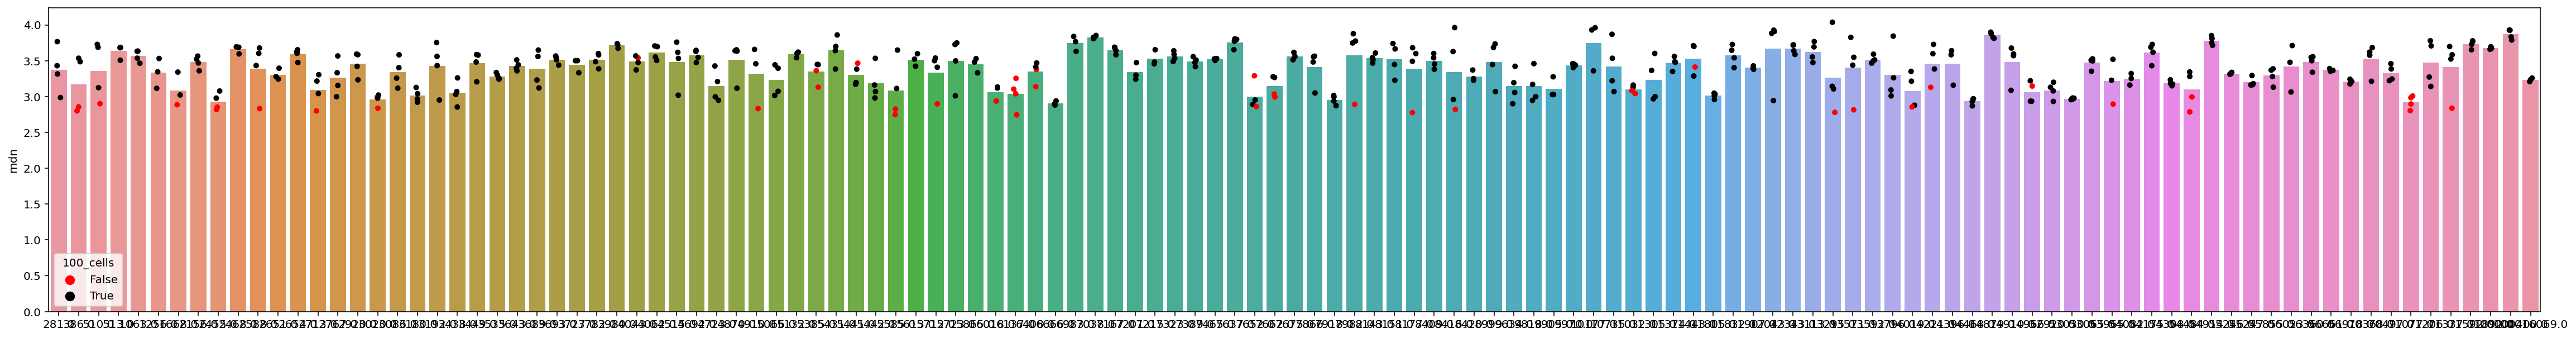

In [20]:
plt.figure(figsize=(40,5))
sns.barplot(data=wt_median_df, x='orf_id',y='mdn', ci=None)
sns.stripplot(data=wt_median_df, x='orf_id',y='mdn', hue='100_cells', palette={True:'black', False:'red'})
plt.xlabel('')
plt.show()

In [21]:
pDEST_DUAL_expr_df = pDEST_DUAL_df[(pDEST_DUAL_df.mCherry_log10 >= (3.487 - 0.5))&(pDEST_DUAL_df.mCherry_log10 <= (3.487 + 0.5))].copy()
# print(len(pDEST_DUAL_expr_df))
# n_cell_d = dict(pDEST_DUAL_expr_df.coordinates.value_counts())

# pDEST_DUAL_expr_df['n_cells_post'] = pDEST_DUAL_expr_df.coordinates.map(n_cell_d)
# pDEST_DUAL_expr_df['frac_post'] = pDEST_DUAL_expr_df.n_cells_post / pDEST_DUAL_expr_df.n_cells
# pDEST_DUAL_expr_df['at_least_200'] = pDEST_DUAL_expr_df.n_cells_post >= 200

#pDEST_DUAL_expr_df = pDEST_DUAL_expr_df[pDEST_DUAL_expr_df.at_least_400].copy()
#print(len(pDEST_DUAL_expr_df))
pDEST_DUAL_expr_df.head()

,GFP,mCherry,pla,well,orf_id,mut_id,node_type,dest_pla_id,exp_plate,exp_well,nt_change,aa_change,clinical_significance,symbol,GFP_mCherry_ratio,GFP_log10,mCherry_log10,coordinates,n_cells
0,89.889999,5822.839844,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-6.017419,1.953711,3.765135,"(24, E10)",10878
1,143.289993,3914.760010,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-4.771914,2.156216,3.592705,"(24, E10)",10878
3,43.610001,1321.920044,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-4.921832,1.639586,3.121205,"(24, E10)",10878
4,86.330002,2043.400024,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-4.564966,1.936162,3.310353,"(24, E10)",10878
6,100.570000,4392.120117,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-5.448646,2.002468,3.642674,"(24, E10)",10878


In [22]:
pDEST_DUAL_expr_WT_df = pDEST_DUAL_expr_df.query("nt_change == 'WT' and GFP_log10 >= 2").copy()
n_cell_d = dict(pDEST_DUAL_expr_WT_df.coordinates.value_counts())
pDEST_DUAL_expr_WT_df['n_cells_post'] = pDEST_DUAL_expr_WT_df.coordinates.map(n_cell_d)
pDEST_DUAL_expr_WT_df['frac_post'] = pDEST_DUAL_expr_WT_df.n_cells_post / pDEST_DUAL_expr_WT_df.n_cells
pDEST_DUAL_expr_WT_df['at_least_200'] = pDEST_DUAL_expr_WT_df.n_cells_post >= 200

pDEST_DUAL_expr_WT_df.head()

,GFP,mCherry,pla,well,orf_id,mut_id,node_type,dest_pla_id,exp_plate,exp_well,nt_change,aa_change,clinical_significance,symbol,GFP_mCherry_ratio,GFP_log10,mCherry_log10,coordinates,n_cells,n_cells_post,frac_post,at_least_200
1,143.289993,3914.760010,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-4.771914,2.156216,3.592705,"(24, E10)",10878,4831,0.444107,True
6,100.570000,4392.120117,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-5.448646,2.002468,3.642674,"(24, E10)",10878,4831,0.444107,True
7,159.309998,7330.399902,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-5.523983,2.202243,3.865128,"(24, E10)",10878,4831,0.444107,True
13,245.639999,2326.959961,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-3.243829,2.390299,3.366789,"(24, E10)",10878,4831,0.444107,True
14,236.739990,1790.440063,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-2.918939,2.374272,3.252960,"(24, E10)",10878,4831,0.444107,True


In [23]:
df_l = []
for orf_id in pDEST_DUAL_expr_df.orf_id.unique():
    if orf_id > 0:
        
        sub_df = pDEST_DUAL_expr_df.query(f'orf_id == {orf_id} and mut_id == 0 and GFP_log10 >= 2').copy()
        n_cell_d = dict(sub_df.coordinates.value_counts())
        sub_df['n_cells_post'] = sub_df.coordinates.map(n_cell_d)
        sub_df['frac_post'] = sub_df.n_cells_post / sub_df.n_cells
        sub_df = sub_df[(sub_df.frac_post >= 0.237)&(sub_df.n_cells_post>=100)]
        #sub_df['at_least_200'] = sub_df.n_cells_post >= 200
    
        min_wt_n = sub_df.n_cells_post.min()
        wt_l = sub_df.aa_change.unique().tolist()
        
        if min_wt_n >= 100 and len(wt_l) > 1:
            #print(orf_id, min_wt_n, wt_l)
            wt_df = pd.concat([sub_df[sub_df.aa_change == wt].sample(n=min_wt_n, random_state=1) for wt in wt_l])
            allele_df = pDEST_DUAL_expr_df.query(f'orf_id == {orf_id} and mut_id > 0')
            
            df_l.append(wt_df)
            df_l.append(allele_df)
        
reduced_df = pd.concat(df_l)
reduced_df['aa_change_r'] = reduced_df.aa_change.apply(lambda x: x if 'WT' not in x else 'WT')
reduced_df.head()

,GFP,mCherry,pla,well,orf_id,mut_id,node_type,dest_pla_id,exp_plate,exp_well,nt_change,aa_change,clinical_significance,symbol,GFP_mCherry_ratio,GFP_log10,mCherry_log10,coordinates,n_cells,n_cells_post,frac_post,aa_change_r
5005,223.389999,977.840027,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-2.130034,2.349064,2.990268,"(24, E10)",10878,4831.0,0.444107,WT
2379,178.000000,3895.719971,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-4.451941,2.250420,3.590588,"(24, E10)",10878,4831.0,0.444107,WT
1005,134.389999,8751.599609,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-6.025049,2.128367,3.942087,"(24, E10)",10878,4831.0,0.444107,WT
7672,210.039993,3870.560059,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-4.203806,2.322302,3.587774,"(24, E10)",10878,4831.0,0.444107,WT
1386,140.619995,1363.400024,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-3.277335,2.148047,3.134623,"(24, E10)",10878,4831.0,0.444107,WT


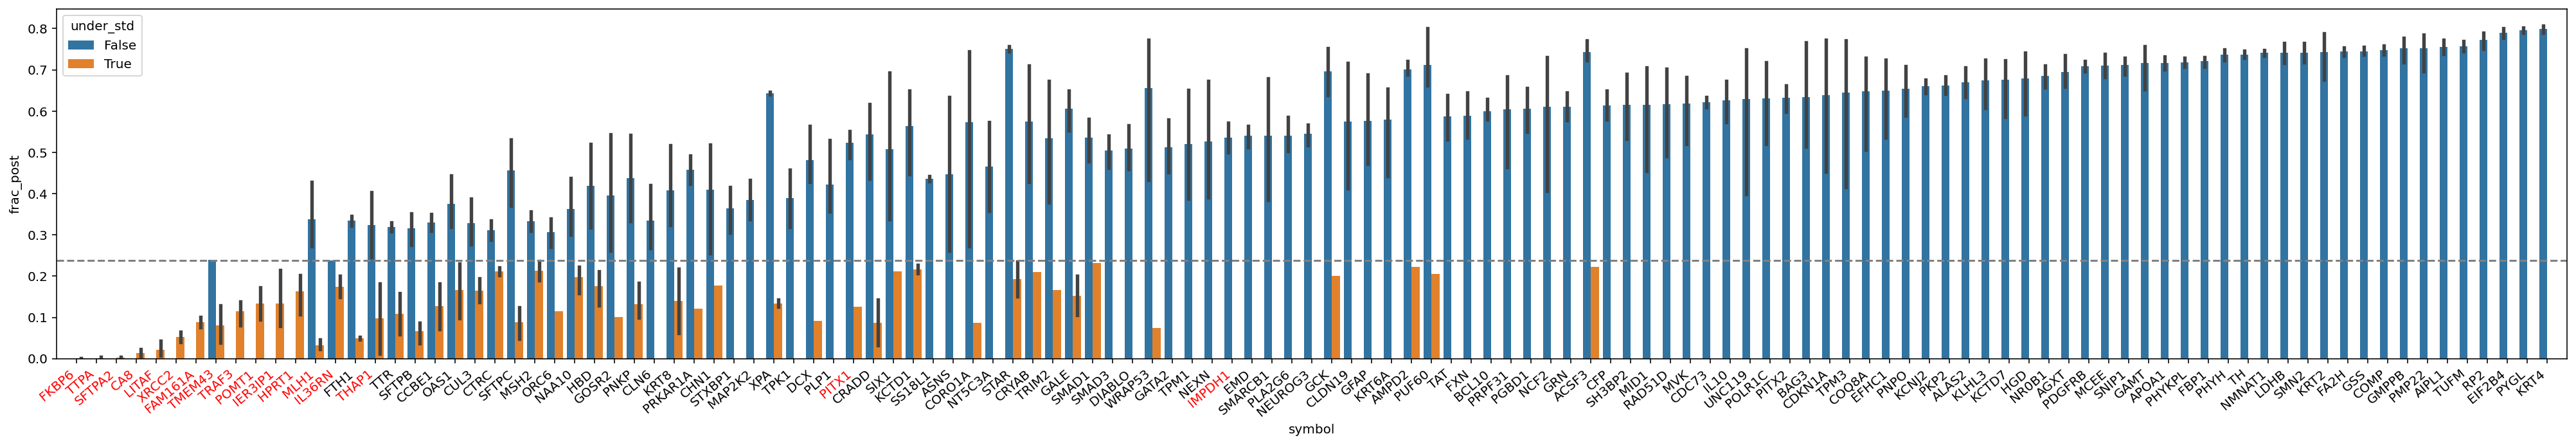

In [24]:
df = pDEST_DUAL_expr_WT_df[['symbol','aa_change','frac_post']].drop_duplicates().copy()
mean_d = dict(df.groupby('symbol').frac_post.mean())
df['mean_frac'] = df.symbol.map(mean_d)

frac_mean = df.frac_post.mean()
frac_std = np.std(df.frac_post)

df['under_std'] = df.frac_post.apply(lambda x: x<=(-frac_std)+frac_mean)

df.sort_values(by='mean_frac',inplace=True)
fig, ax = plt.subplots(figsize=(35,5))
ax = sns.barplot(data=df, x='symbol', y='frac_post',  hue='under_std')
ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha='right');
#ax.hlines(y=df.frac_post.mean(), xmax=df.symbol.nunique(), xmin=-1, color='lightgrey', linestyles='--')

ax.hlines(y=(-frac_std)+frac_mean, xmax=df.symbol.nunique(), xmin=-1, color='grey', linestyles='--')
ax.set_xlim(-1,df.symbol.nunique())

failed_genes = set(pDEST_DUAL_df.symbol) - set(reduced_df[reduced_df.node_type == 'wt'].symbol)
for xtick in ax.get_xticklabels():
    symbol = xtick.get_text()
    color = 'black' if symbol not in failed_genes else 'red'
    xtick.set_color(color)



plt.show()

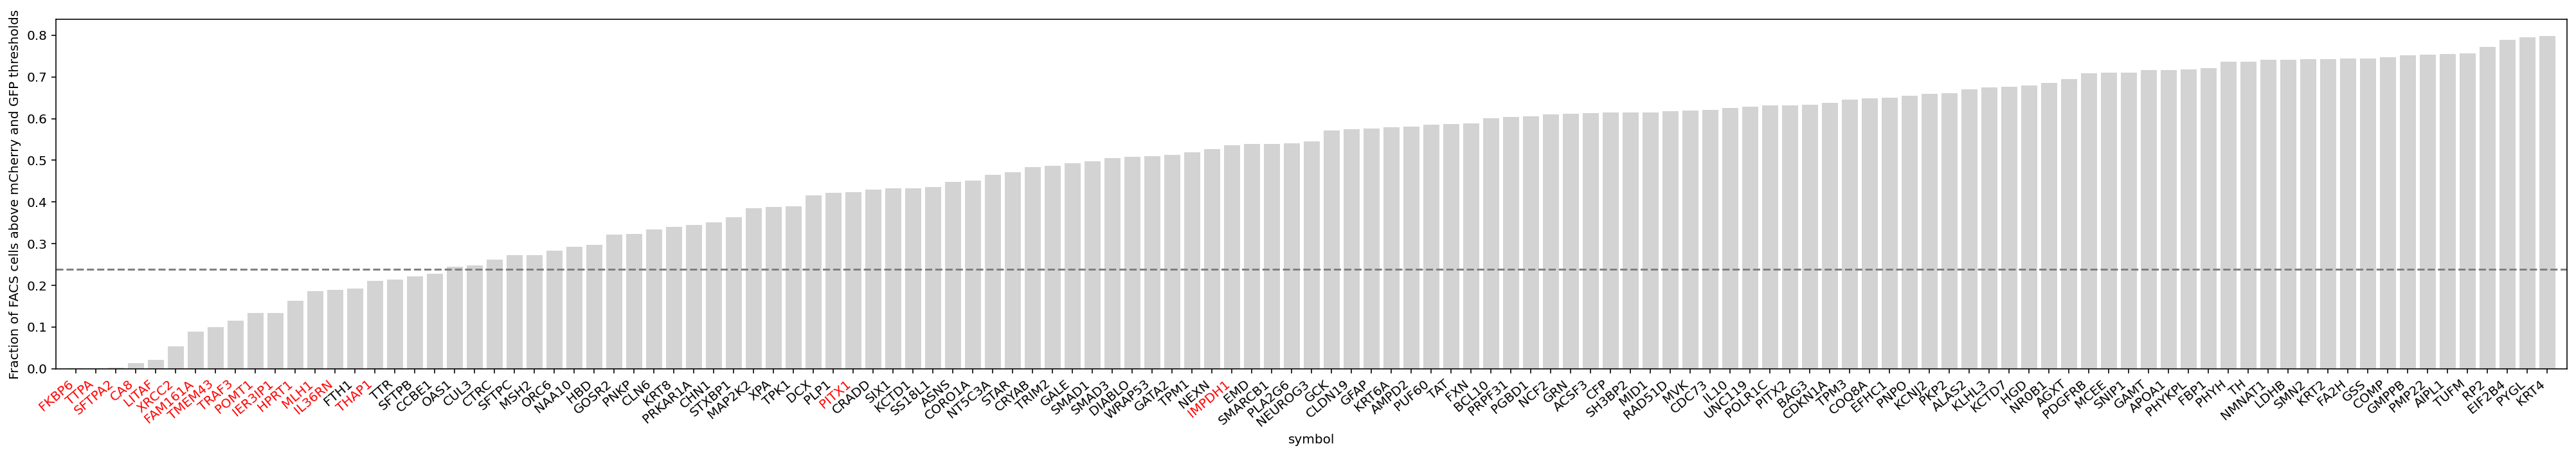

In [25]:
df = pDEST_DUAL_expr_WT_df[['symbol','aa_change','frac_post']].drop_duplicates().copy()
mean_d = dict(df.groupby('symbol').frac_post.mean())
df['mean_frac'] = df.symbol.map(mean_d)

frac_mean = df.frac_post.mean()
frac_std = np.std(df.frac_post)

df['under_std'] = df.frac_post.apply(lambda x: x<=(-frac_std)+frac_mean)

df.sort_values(by='mean_frac',inplace=True)
fig, ax = plt.subplots(figsize=(35,5))
ax = sns.barplot(data=df, x='symbol', y='frac_post',  color='lightgrey', ci=False)
ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha='right');
#ax.hlines(y=df.frac_post.mean(), xmax=df.symbol.nunique(), xmin=-1, color='lightgrey', linestyles='--')

ax.hlines(y=(-frac_std)+frac_mean, xmax=df.symbol.nunique(), xmin=-1, color='grey', linestyles='--')
ax.set_xlim(-1,df.symbol.nunique())

failed_genes = set(pDEST_DUAL_df.symbol) - set(reduced_df[reduced_df.node_type == 'wt'].symbol)
for xtick in ax.get_xticklabels():
    symbol = xtick.get_text()
    color = 'black' if symbol not in failed_genes else 'red'
    xtick.set_color(color)

ax.set_ylabel('Fraction of FACS cells above mCherry and GFP thresholds')

plt.show()

#### send genes to sequencing

In [26]:
failed_df = pdest_layout_df.query(f"mut_id == 0 and symbol.isin({[e for e in failed_genes if e == e]})").sort_values(by=['exp_plate','exp_well']).copy()

q = f'''select distinct orf_id, cds from horfeome.cdna where orf_id in ({', '.join(str(int(o)) for o in failed_df.orf_id.unique())})'''
orf_len_df = GetDFv2(q,['orf_id','cds'])
orf_len_df['length'] = orf_len_df.cds.apply(len)
failed_df['orf_length'] = failed_df.orf_id.map(dict(zip(orf_len_df.orf_id, orf_len_df.length)))
failed_df.to_csv('failed_pdest_wt_orfs.csv')
failed_df.head()

,orf_id,mut_id,node_type,dest_pla_id,exp_plate,exp_well,nt_change,aa_change,clinical_significance,symbol,orf_length
109,10177.0,0.0,wt,2,VUSDUALXP_02,B02,WT,WT,WT,FKBP6,981
121,10177.0,0.0,wt,2,VUSDUALXP_02,C02,WT,WT,WT,FKBP6,981
168,10177.0,0.0,wt,2,VUSDUALXP_02,G01,WT,WT,WT,FKBP6,981
180,10177.0,0.0,wt,2,VUSDUALXP_02,H01,WT,WT,WT,FKBP6,981
235,8151.0,0.0,wt,3,VUSDUALXP_03,D08,WT,WT,WT,IL36RN,465


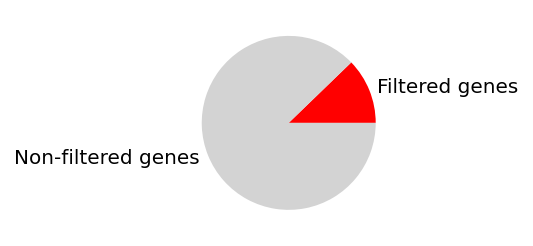

In [27]:
plt.figure(figsize=(2,2))
plt.pie([17,122], labels=['Filtered genes','Non-filtered genes'], colors=['red','lightgrey']);

In [28]:
17/122

0.13934426229508196

In [29]:
df[df.symbol == 'IMPDH1']

,symbol,aa_change,frac_post,mean_frac,under_std
9053737,IMPDH1,WT_4,0.500000,0.535714,False
11466500,IMPDH1,WT_2,0.571429,0.535714,False


In [30]:
frac_mean = df.frac_post.mean()
frac_std = np.std(df.frac_post)

(-frac_std)+frac_mean

0.23780414103494846

In [31]:
df.frac_post.mean()

0.4829798582645498

In [32]:
pDEST_DUAL_df[pDEST_DUAL_df.node_type=='wt'].mCherry_log10.median()

3.4835872969688944

In [33]:
pDEST_DUAL_expr_df.mCherry_log10.median()

3.496569878695236

In [34]:
pDEST_DUAL_df.mCherry_log10.median()

3.4871666604487888

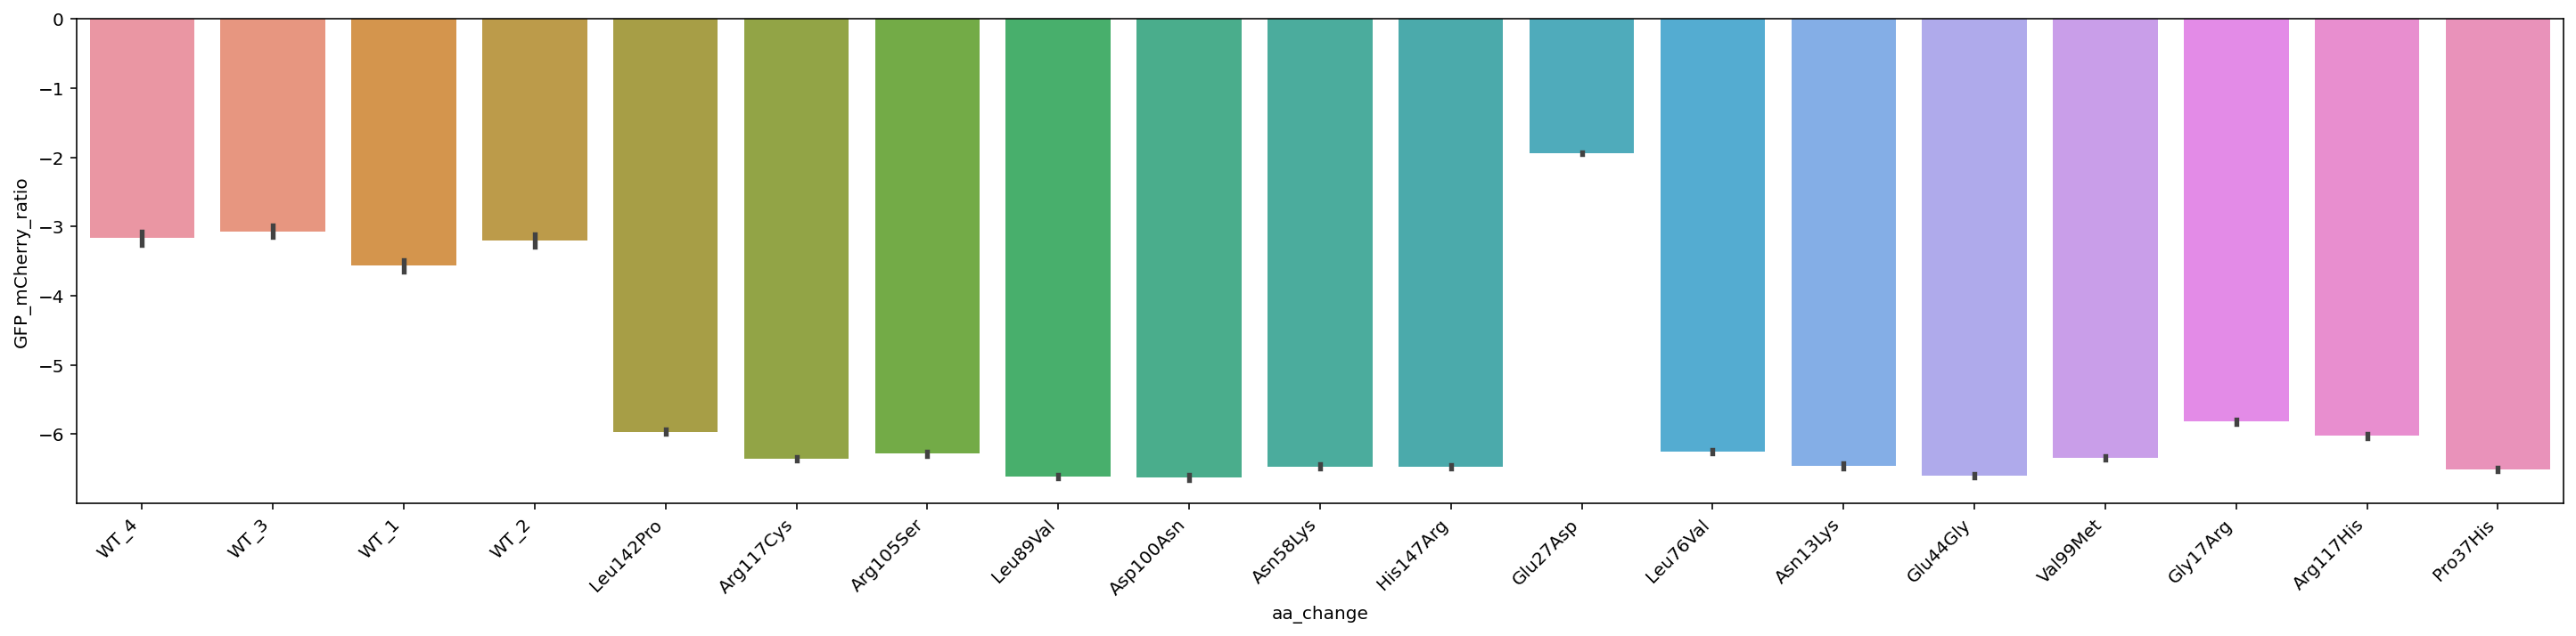

In [35]:
plt.figure(figsize=(25,5))
ax = sns.barplot(data=reduced_df.query('symbol == "HBD"'), x='aa_change', y='GFP_mCherry_ratio')
plt.xticks(rotation=45, ha='right')
plt.show()

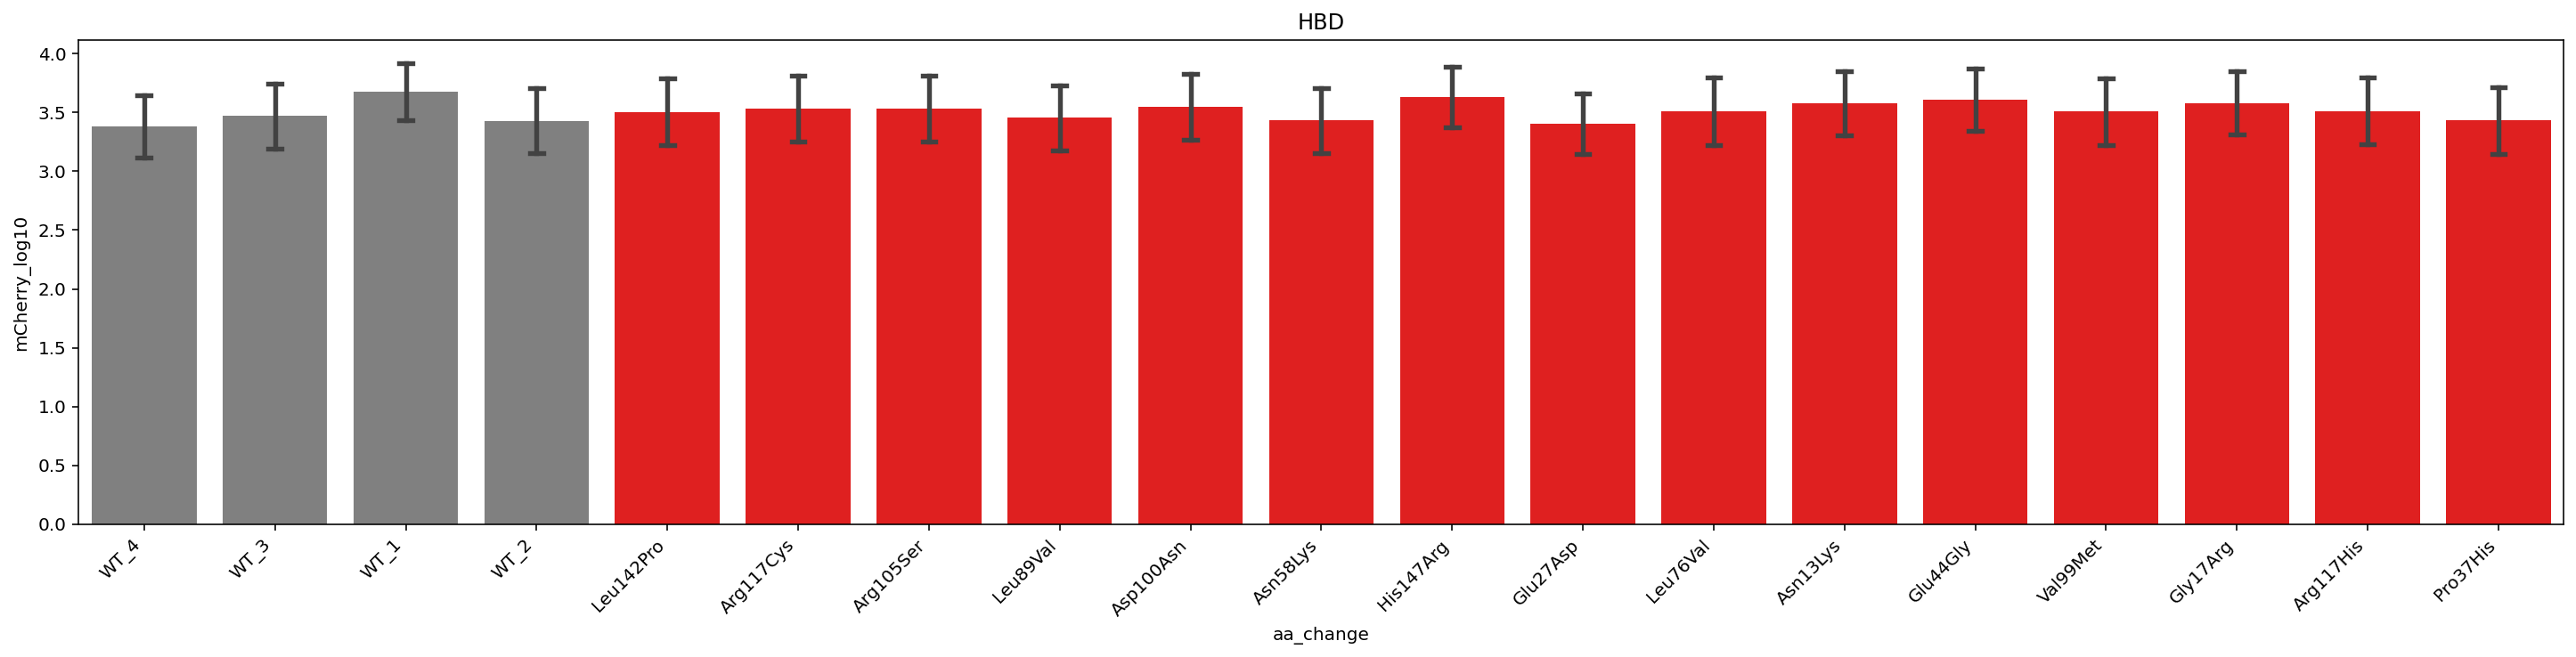

In [36]:
plt.figure(figsize=(25,5))
plt.title('HBD')
cs_d = {'WT':'grey', 'VUS':'blue', 'Pathogenic':'red', 'Benign':'green', 'Conflicting':'lightgrey', None:'lightgrey', 'other':'lightgrey','to_be_verified':'lightgrey'}
palette = {aa_change:cs_d[cs] for aa_change, cs in zip(reduced_df.query('symbol == "HBD"').aa_change,reduced_df.query('symbol == "HBD"').clinical_significance)}
ax = sns.barplot(data=reduced_df.query('symbol == "HBD"'), x='aa_change', y='mCherry_log10', ci='sd', capsize=0.1, palette=palette)
plt.xticks(rotation=45, ha='right')
plt.show()

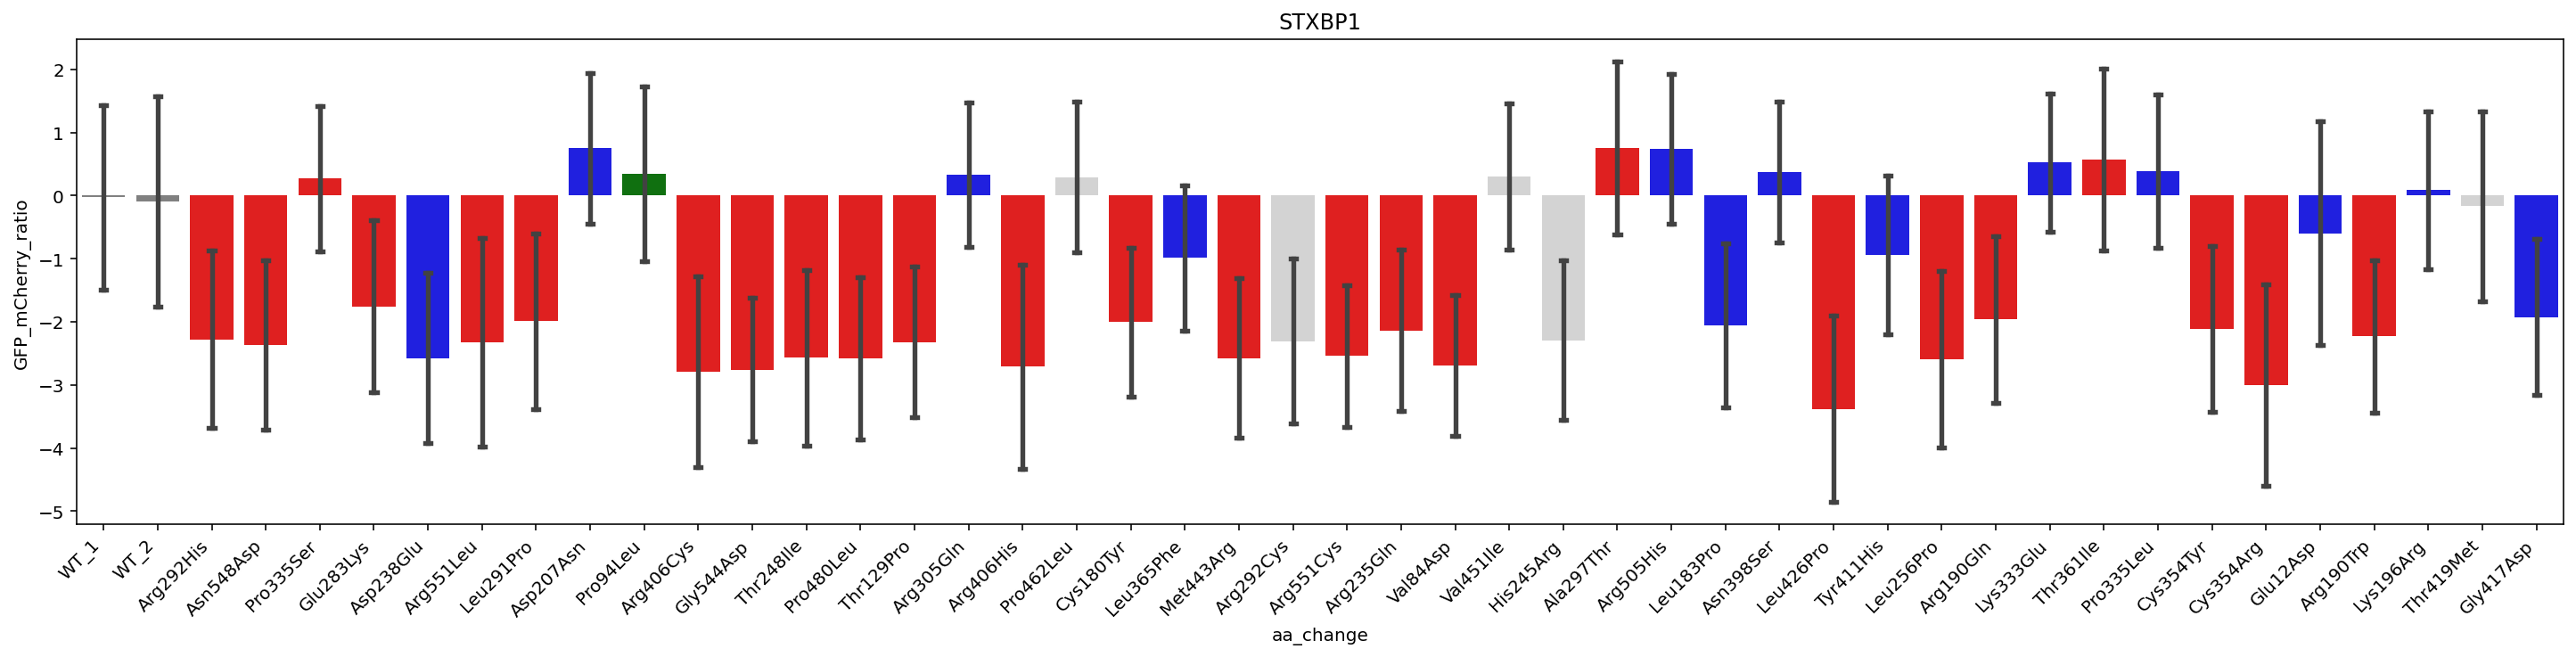

In [37]:
plt.figure(figsize=(25,5))
plt.title('STXBP1')
cs_d = {'WT':'grey', 'VUS':'blue', 'Pathogenic':'red', 'Benign':'green', 'Conflicting':'lightgrey', None:'lightgrey', 'other':'lightgrey','to_be_verified':'lightgrey'}
palette = {aa_change:cs_d[cs] for aa_change, cs in zip(reduced_df.query('symbol == "STXBP1"').aa_change,reduced_df.query('symbol == "STXBP1"').clinical_significance)}
ax = sns.barplot(data=reduced_df.query('symbol == "STXBP1"'), x='aa_change', y='GFP_mCherry_ratio', ci='sd', capsize=0.1, palette=palette)
plt.xticks(rotation=45, ha='right')
plt.show()

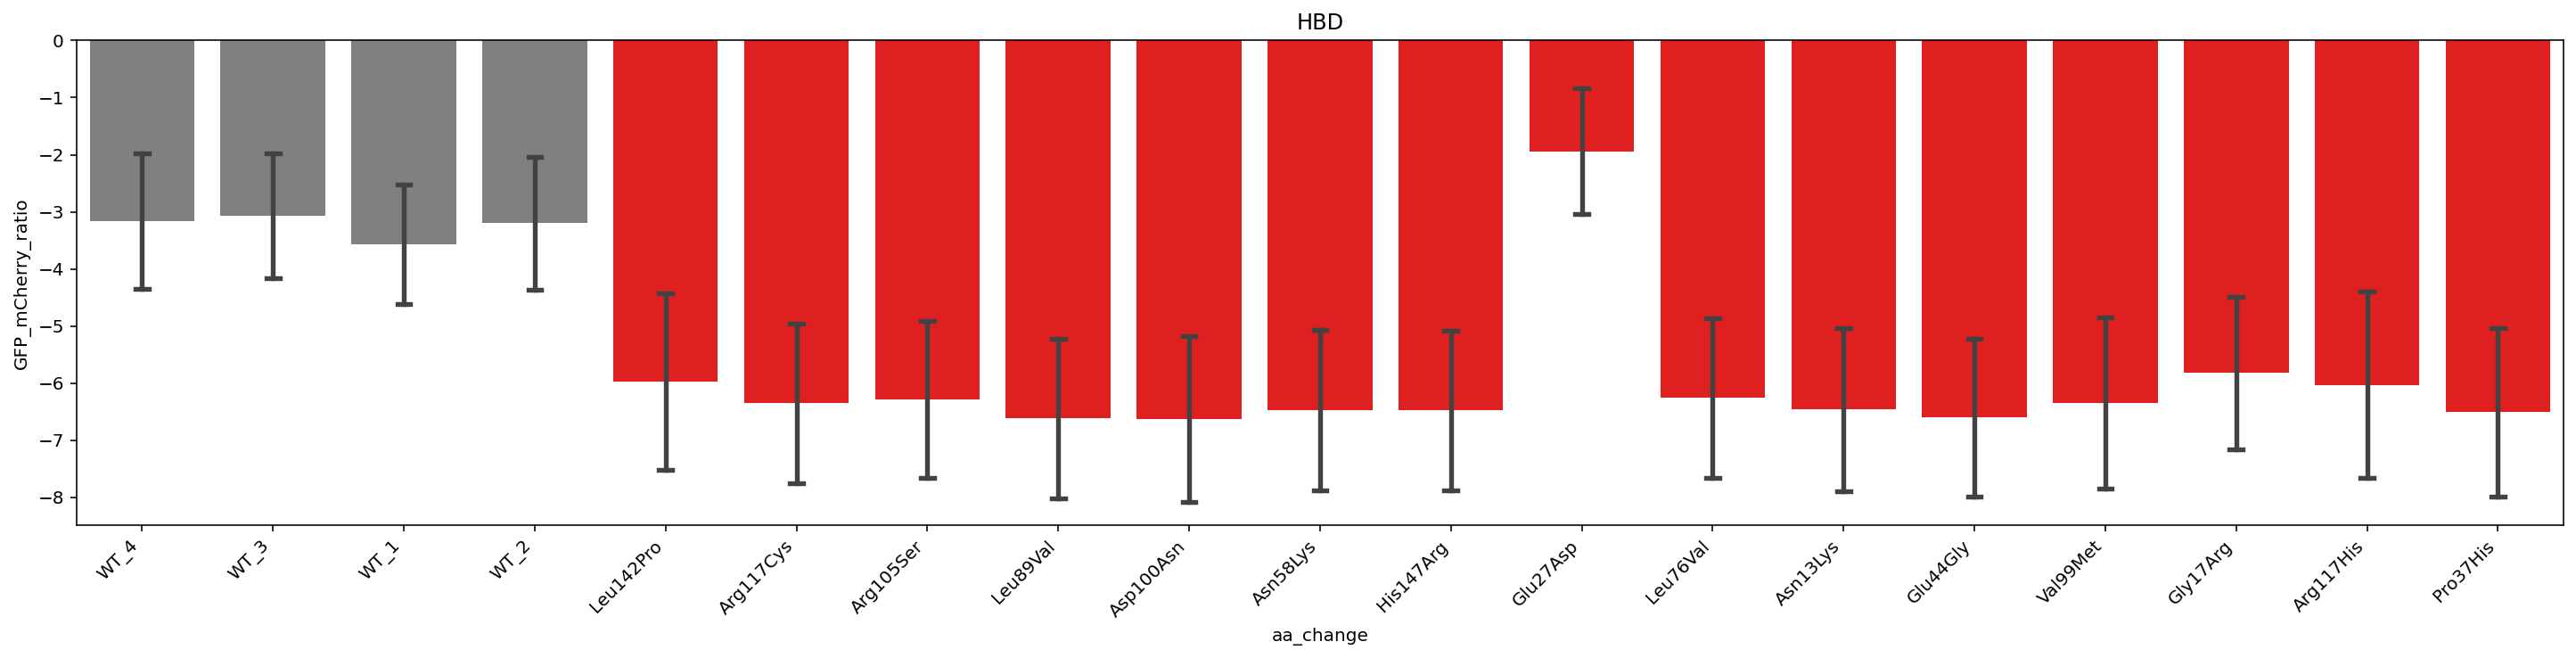

In [38]:
plt.figure(figsize=(25,5))
plt.title('HBD')
cs_d = {'WT':'grey', 'VUS':'blue', 'Pathogenic':'red', 'Benign':'green', 'Conflicting':'lightgrey', None:'lightgrey', 'other':'lightgrey','to_be_verified':'lightgrey'}
palette = {aa_change:cs_d[cs] for aa_change, cs in zip(reduced_df.query('symbol == "HBD"').aa_change,reduced_df.query('symbol == "HBD"').clinical_significance)}
ax = sns.barplot(data=reduced_df.query('symbol == "HBD"'), x='aa_change', y='GFP_mCherry_ratio', ci='sd', capsize=0.1, palette=palette)
plt.xticks(rotation=45, ha='right')
plt.show()

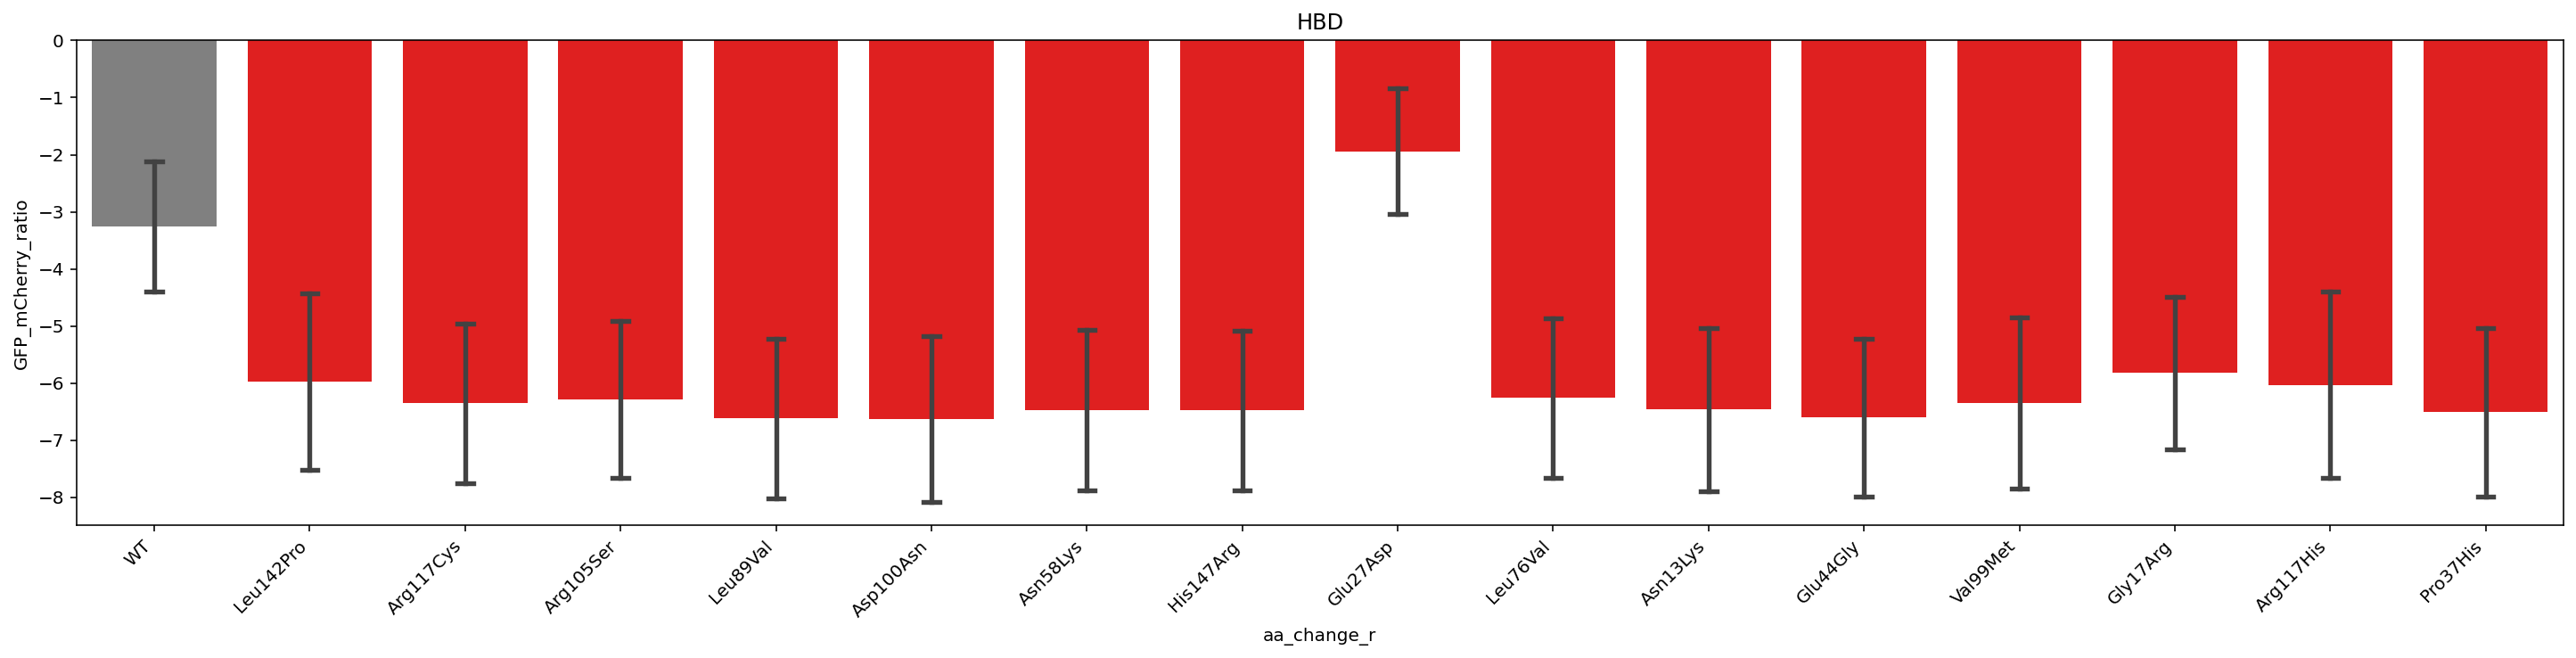

In [39]:
plt.figure(figsize=(25,5))
plt.title('HBD')
cs_d = {'WT':'grey', 'VUS':'blue', 'Pathogenic':'red', 'Benign':'green', 'Conflicting':'lightgrey', None:'lightgrey', 'other':'lightgrey','to_be_verified':'lightgrey'}
palette = {aa_change_r:cs_d[cs] for aa_change_r, cs in zip(reduced_df.query('symbol == "HBD"').aa_change_r,reduced_df.query('symbol == "HBD"').clinical_significance)}
ax = sns.barplot(data=reduced_df.query('symbol == "HBD"'), x='aa_change_r', y='GFP_mCherry_ratio', ci='sd', capsize=0.1, palette=palette)
plt.xticks(rotation=45, ha='right')
plt.show()

In [40]:
from scipy.stats import ks_2samp

In [41]:
mlh1_df = reduced_df.query("symbol == 'MLH1'")

for aa_change_r in mlh1_df.aa_change_r.unique():
    #ks_2samp(data1, data2)
    if aa_change_r != 'WT':
        ks = ks_2samp(mlh1_df[mlh1_df.aa_change_r == 'WT'].GFP_mCherry_ratio,#mCherry_log10,
                      mlh1_df[mlh1_df.aa_change_r == aa_change_r].GFP_mCherry_ratio#mCherry_log10
                     )
        
        print(aa_change_r, ks)

## Allele WT ratios

In [42]:
reduced_df.query("clinical_significance == 'WT'").symbol.value_counts()

TUFM       30760
PDGFRB     29888
EIF2B4     29288
KRT4       29144
PHYH       28836
FA2H       27608
PYGL       27156
AIPL1      26944
PKP2       26820
EFHC1      26596
EMD        25880
RP2        25508
KCTD7      25500
SMN2       25464
COMP       24813
FBP1       23836
IL10       23832
APOA1      23820
GAMT       23631
NCF2       23097
MCEE       22420
GSS        22119
LDHB       21752
NMNAT1     21717
TPM3       21387
COQ8A      20757
TH         20664
PHYKPL     20632
CFP        20440
MID1       19434
ACSF3      19341
CDC73      19208
BCL10      19084
UNC119     18552
NR0B1      18321
NEUROG3    18108
PUF60      17958
GMPPB      17428
GCK        17108
WRAP53     17104
GATA2      16996
PLA2G6     16148
GRN        15918
PITX2      15483
SNIP1      15267
XPA        14848
CORO1A     14638
STAR       14552
SS18L1     14528
DIABLO     14384
ALAS2      14211
PLP1       12204
ASNS       12178
AMPD2      11932
PGBD1      11388
KRT2       11388
HGD        11136
POLR1C     10652
KCTD1      104

In [43]:
len(reduced_df)

8447027

In [44]:
len(reduced_df)

8447027

In [75]:
res = []
for orf_id in reduced_df.orf_id.unique():
    if orf_id > 0:
        
        sub_df = reduced_df.query(f'orf_id == {orf_id}')
        wt_gfp_mcherry_ratio = sub_df.query('mut_id == 0').GFP_mCherry_ratio.mean()
        
        info_d = {(orf_id,aa_change_r):(nt_change,clinical_significance) for orf_id,aa_change_r,nt_change,clinical_significance in zip(sub_df.orf_id,
                                                                                                                                       sub_df.aa_change_r,
                                                                                                                                       sub_df.nt_change,
                                                                                                                                       sub_df.clinical_significance
                                                                                                                                       )}
        
        
        for aa_change_r in sub_df.aa_change_r.unique():
            if aa_change_r != 'WT':
                allele_gfp_mcherry_ratio  = sub_df.query(f'aa_change_r == "{aa_change_r}"').GFP_mCherry_ratio.mean()
                res.append([orf_id, 
                            aa_change_r, 
                            info_d[orf_id,aa_change_r][0],
                            info_d[orf_id,aa_change_r][1],
                            wt_gfp_mcherry_ratio, 
                            allele_gfp_mcherry_ratio, 
                            np.log2((2**allele_gfp_mcherry_ratio)/(2**wt_gfp_mcherry_ratio)), 
                            len(sub_df.query('mut_id == 0')), 
                            len(sub_df.query('aa_change_r == "{aa_change_r}"'))
                           ])
        

allele_wt_ratio_df = pd.DataFrame(res, columns=['orf_id', 'aa_change', 'nt_change', 'clinical_significance', 'wt_gfp_mcherry_ratio' ,'allele_gfp_mcherry_ratio','allele_wt_ratio','n_wt','n_allele'])
allele_wt_ratio_df['symbol'] = allele_wt_ratio_df.orf_id.map(orf_to_symbol)
allele_wt_ratio_df = allele_wt_ratio_df.query(f"symbol not in {[e for e in failed_genes if e == e]}").copy()

mean_benign_allele_wt_ratio = np.mean(allele_wt_ratio_df.query("clinical_significance == 'Benign'").allele_wt_ratio)
std_benign_allele_wt_ratio = np.std(allele_wt_ratio_df.query("clinical_significance == 'Benign'").allele_wt_ratio)

allele_wt_ratio_df['z_score'] = allele_wt_ratio_df.allele_wt_ratio.apply(lambda x: (x-mean_benign_allele_wt_ratio)/std_benign_allele_wt_ratio)
allele_wt_ratio_df['Stability impact'] = allele_wt_ratio_df.z_score.apply(lambda x: 'Destabilizing' if x <= -1 else 'Stabilizing' if x >=  1 else 'No effect')
allele_wt_ratio_df['Stability impact'] = allele_wt_ratio_df.z_score.apply(lambda x: 'Unstable' if x <= -1 else 'Stable')
allele_wt_ratio_df['experiment_id'] = list(zip(allele_wt_ratio_df.orf_id,allele_wt_ratio_df.nt_change))
allele_wt_ratio_df.head()

,orf_id,aa_change,nt_change,clinical_significance,wt_gfp_mcherry_ratio,allele_gfp_mcherry_ratio,allele_wt_ratio,n_wt,n_allele,symbol,z_score,Stability impact,experiment_id
0,55247.0,Ser162Gly,484A>G,other,-3.761045,-5.317992,-1.556948,2175,0,OAS1,-0.595613,Stable,"(55247.0, 484A>G)"
1,3020.0,Glu313Lys,937G>A,Pathogenic,-0.601091,-3.012488,-2.411397,1192,0,CHN1,-1.181620,Unstable,"(3020.0, 937G>A)"
2,3020.0,Pro252Ser,754C>T,Pathogenic,-0.601091,-2.850184,-2.249092,1192,0,CHN1,-1.070306,Unstable,"(3020.0, 754C>T)"
3,3020.0,Ala223Val,668C>T,Pathogenic,-0.601091,-2.903849,-2.302757,1192,0,CHN1,-1.107111,Unstable,"(3020.0, 668C>T)"
4,3020.0,Leu20Phe,60A>T,Pathogenic,-0.601091,-2.687816,-2.086725,1192,0,CHN1,-0.958950,Stable,"(3020.0, 60A>T)"


In [46]:
allele_wt_ratio_df.wt_gfp_mcherry_ratio.min()

-4.598518365330335

In [47]:
allele_wt_ratio_df[allele_wt_ratio_df.symbol == 'OAS1']

,orf_id,aa_change,nt_change,clinical_significance,wt_gfp_mcherry_ratio,allele_gfp_mcherry_ratio,allele_wt_ratio,n_wt,n_allele,symbol,z_score,stability,experiment_id
0,55247.0,Ser162Gly,484A>G,other,-3.761045,-5.317992,-1.556948,2175,0,OAS1,-0.595613,no effect,"(55247.0, 484A>G)"


### OUTPUT TABLES

In [48]:
output tables?
reduced_df.to_csv('processed_data_tables/pdest_reduced_table.tsv', sep='\t', index=None)
allele_wt_ratio_df.to_csv('processed_data_tables/allele_wt_ratio_table.tsv',sep='\t', index=None)

Object `tables` not found.


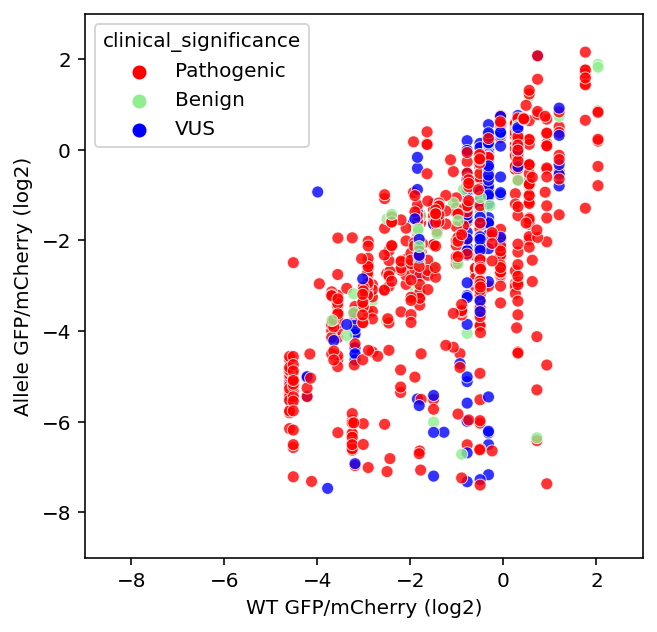

In [49]:
plt.figure(figsize=(5,5))

sns.scatterplot(data=allele_wt_ratio_df.query("clinical_significance.isin(['Pathogenic','Benign','VUS'])"), 
                x='wt_gfp_mcherry_ratio', 
                y='allele_gfp_mcherry_ratio',hue='clinical_significance',alpha=0.8,palette={'Pathogenic':'red','Benign':'lightgreen','VUS':'Blue'})
plt.xlim(-9,3)
plt.ylim(-9,3)
plt.xlabel('WT GFP/mCherry (log2)')
plt.ylabel('Allele GFP/mCherry (log2)')
plt.show()

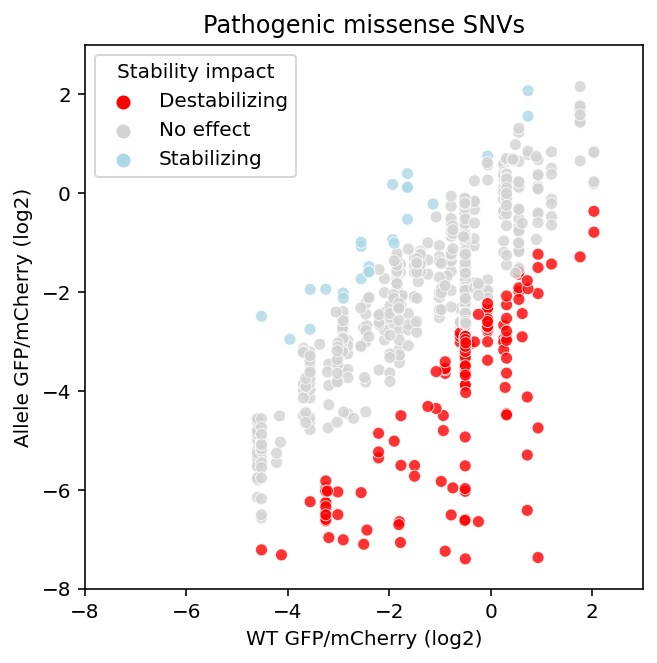

In [72]:
stability_color_d = {'Destabilizing':'red','No effect':'Lightgrey','Stabilizing':'lightblue'}
plt.figure(figsize=(5,5))

sns.scatterplot(data=allele_wt_ratio_df.query("clinical_significance.isin(['Pathogenic'])"), 
                x='wt_gfp_mcherry_ratio', 
                y='allele_gfp_mcherry_ratio',
                hue='Stability impact',
                alpha=0.8,
                palette=stability_color_d
               )
plt.title('Pathogenic missense SNVs')
plt.xlim(-8,3)
plt.ylim(-8,3)
plt.xlabel('WT GFP/mCherry (log2)')
plt.ylabel('Allele GFP/mCherry (log2)')

plt.show()

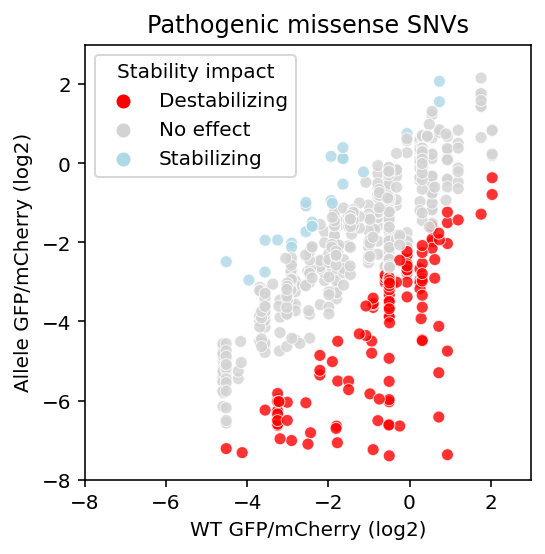

In [73]:
stability_color_d = {'Destabilizing':'red','No effect':'Lightgrey','Stabilizing':'lightblue'}
plt.figure(figsize=(4,4))

sns.scatterplot(data=allele_wt_ratio_df.query("clinical_significance.isin(['Pathogenic'])"), 
                x='wt_gfp_mcherry_ratio', 
                y='allele_gfp_mcherry_ratio',
                hue='Stability impact',
                alpha=0.8,
                palette=stability_color_d
               )
plt.title('Pathogenic missense SNVs')
plt.xlim(-8,3)
plt.ylim(-8,3)
plt.xlabel('WT GFP/mCherry (log2)')
plt.ylabel('Allele GFP/mCherry (log2)')

plt.show()

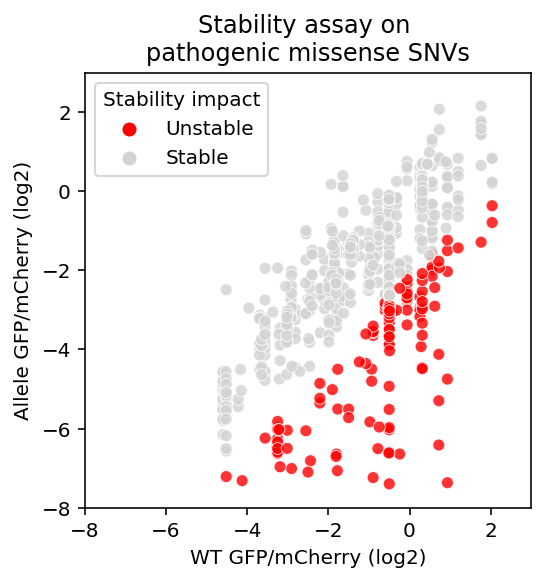

In [80]:
stability_color_d = {'Unstable':'red','Stable':'Lightgrey','Stabilizing':'lightblue'}
plt.figure(figsize=(4,4))

sns.scatterplot(data=allele_wt_ratio_df.query("clinical_significance.isin(['Pathogenic'])"), 
                x='wt_gfp_mcherry_ratio', 
                y='allele_gfp_mcherry_ratio',
                hue='Stability impact',
                alpha=0.8,
                palette=stability_color_d
               )
plt.title('Stability assay on \npathogenic missense SNVs')
plt.xlim(-8,3)
plt.ylim(-8,3)
plt.xlabel('WT GFP/mCherry (log2)')
plt.ylabel('Allele GFP/mCherry (log2)')
plt.savefig('../../../../../../../Desktop/pDEST_scatter.png', bbox_inches='tight', dpi=300)
plt.show()

In [51]:
len(allele_wt_ratio_df[allele_wt_ratio_df.clinical_significance == 'Pathogenic'])

667

In [52]:
allele_wt_ratio_df[allele_wt_ratio_df.allele_wt_ratio > 40]

,orf_id,aa_change,nt_change,clinical_significance,wt_gfp_mcherry_ratio,allele_gfp_mcherry_ratio,allele_wt_ratio,n_wt,n_allele,symbol,z_score,stability,experiment_id


In [53]:
allele_wt_ratio_df[(allele_wt_ratio_df.clinical_significance == 'Benign') & (allele_wt_ratio_df.allele_wt_ratio < -4)]

,orf_id,aa_change,nt_change,clinical_significance,wt_gfp_mcherry_ratio,allele_gfp_mcherry_ratio,allele_wt_ratio,n_wt,n_allele,symbol,z_score,stability,experiment_id
609,56661.0,Gln756Arg,2267A>G,Benign,-1.501546,-6.007742,-4.506196,24813,0,COMP,-2.618295,destabilizing,"(56661.0, 2267A>G)"
828,5865.0,Thr209Met,626C>T,Benign,0.720551,-6.354303,-7.074854,23631,0,GAMT,-4.379957,destabilizing,"(5865.0, 626C>T)"
886,3727.0,Asn419Ile,1256A>T,Benign,-0.897808,-6.718233,-5.820425,23097,0,NCF2,-3.519633,destabilizing,"(3727.0, 1256A>T)"


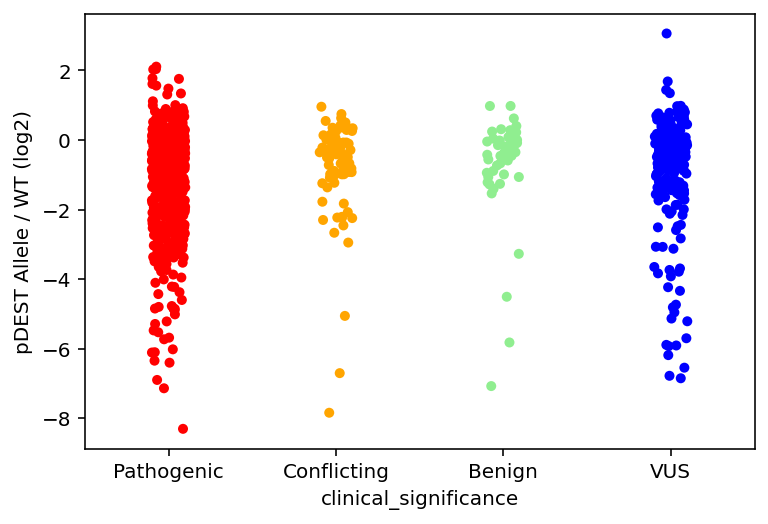

In [54]:
sns.stripplot(data=allele_wt_ratio_df[allele_wt_ratio_df.clinical_significance.isin(['VUS','Pathogenic','Benign','Conflicting'])], 
              x='clinical_significance',
              y='allele_wt_ratio',
              palette={'VUS':'blue','Pathogenic':'r','Benign':'lightgreen','Conflicting':'orange'}
             );
plt.ylabel('pDEST Allele / WT (log2)');

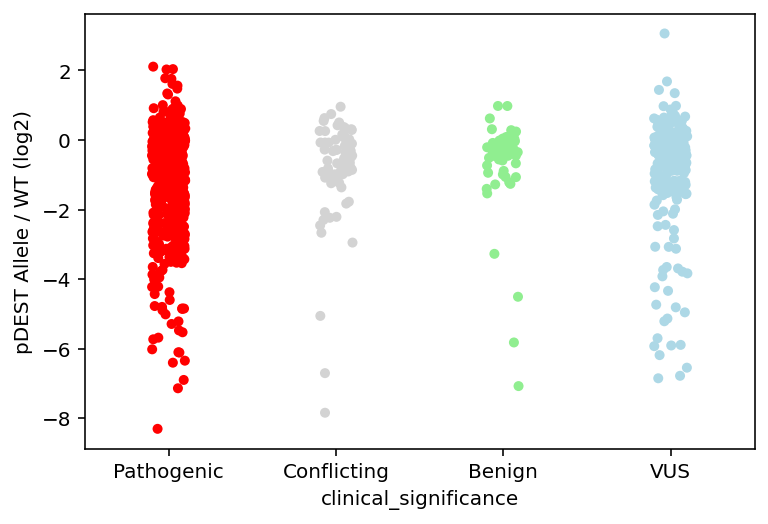

In [55]:
sns.stripplot(data=allele_wt_ratio_df[(allele_wt_ratio_df.clinical_significance.isin(['VUS','Pathogenic','Benign','Conflicting']))&
                                      (allele_wt_ratio_df.symbol != 'STXBP1')
                                     ], 
              x='clinical_significance',
              y='allele_wt_ratio',
              palette={'VUS':'lightblue','Pathogenic':'r','Benign':'lightgreen','Conflicting':'lightgrey'}
             );
plt.ylabel('pDEST Allele / WT (log2)');

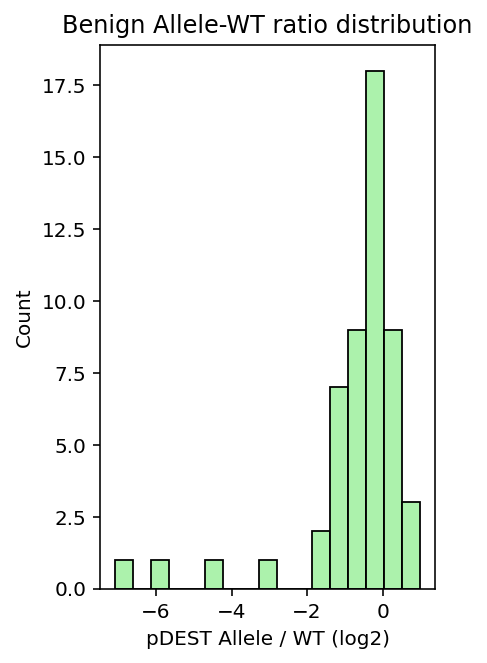

In [56]:
plt.figure(figsize=(3,5))
plt.title('Benign Allele-WT ratio distribution')
sns.histplot(data=allele_wt_ratio_df[allele_wt_ratio_df.clinical_significance.isin(['Benign'])], 
            x='allele_wt_ratio', 
            color = 'lightgreen');

plt.xlabel('pDEST Allele / WT (log2)')
plt.show()

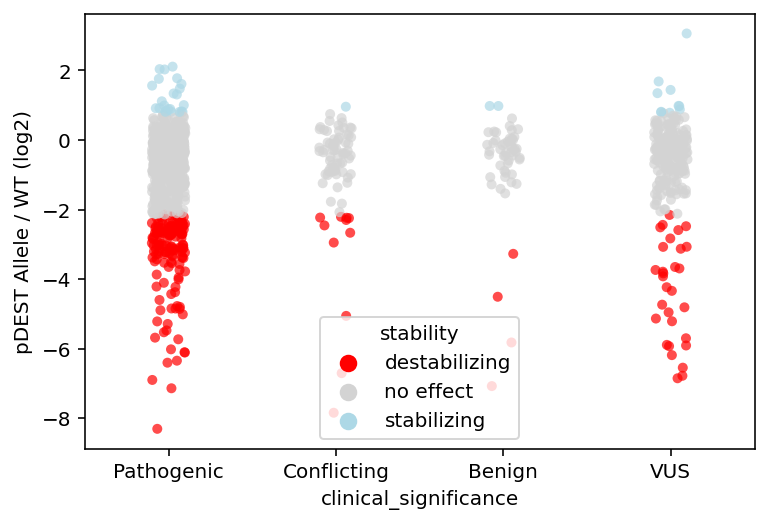

In [57]:
sns.stripplot(data=allele_wt_ratio_df[(allele_wt_ratio_df.clinical_significance.isin(['VUS','Pathogenic','Benign','Conflicting']))
                                     ], 
              x='clinical_significance',
              y='allele_wt_ratio',
              hue='stability',
              palette=stability_color_d,#{'stabilizing':'lightblue','destabilizing':'r','no effect':'lightgrey'},
              alpha=0.7
             );
plt.ylabel('pDEST Allele / WT (log2)');

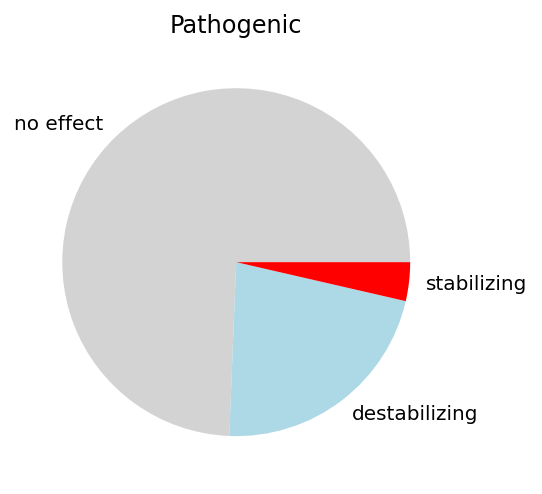

In [58]:
plt.figure()
plt.title('Pathogenic')
allele_wt_ratio_df.query("clinical_significance == 'Pathogenic'").sort_values(by='stability').stability.value_counts().plot.pie(colors=['lightgrey','lightblue','r'])
plt.ylabel('')

plt.show()

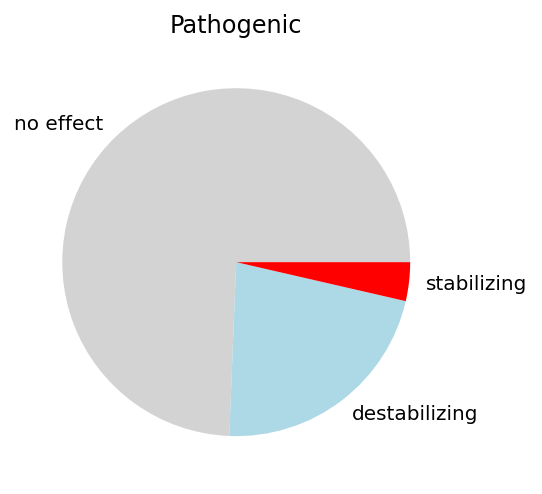

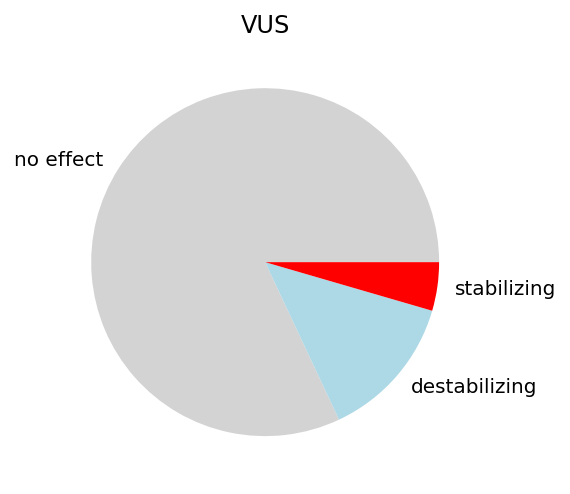

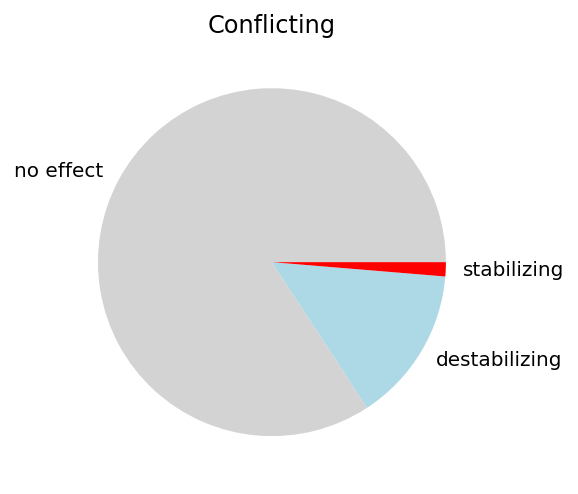

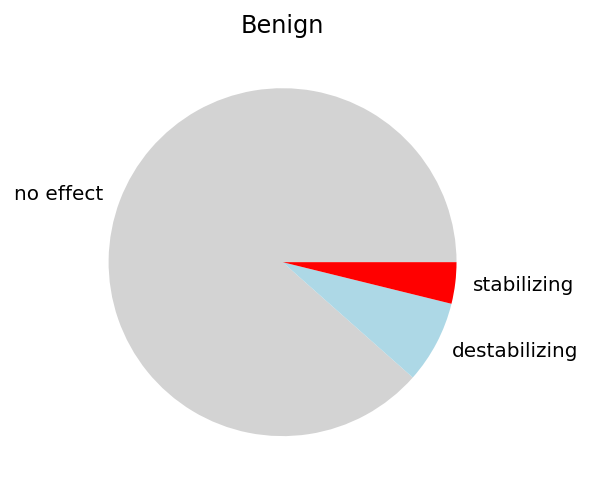

In [59]:
for cs in ['Pathogenic','VUS','Conflicting','Benign']:
    plt.figure()
    plt.title(cs)
    allele_wt_ratio_df.query(f"clinical_significance == '{cs}'").sort_values(by='stability').stability.value_counts().plot.pie(colors=['lightgrey','lightblue','r'])
    plt.ylabel('')

    plt.show()

In [60]:
len(allele_wt_ratio_df[allele_wt_ratio_df.clinical_significance.isin(['Benign'])])

52

In [61]:
reduced_df.head()

,GFP,mCherry,pla,well,orf_id,mut_id,node_type,dest_pla_id,exp_plate,exp_well,nt_change,aa_change,clinical_significance,symbol,GFP_mCherry_ratio,GFP_log10,mCherry_log10,coordinates,n_cells,n_cells_post,frac_post,aa_change_r
5005,223.389999,977.840027,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-2.130034,2.349064,2.990268,"(24, E10)",10878,4831.0,0.444107,WT
2379,178.000000,3895.719971,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-4.451941,2.250420,3.590588,"(24, E10)",10878,4831.0,0.444107,WT
1005,134.389999,8751.599609,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-6.025049,2.128367,3.942087,"(24, E10)",10878,4831.0,0.444107,WT
7672,210.039993,3870.560059,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-4.203806,2.322302,3.587774,"(24, E10)",10878,4831.0,0.444107,WT
1386,140.619995,1363.400024,24,E10,55247.0,0.0,wt,24,VUSDUALXP_24,E10,WT,WT_2,WT,OAS1,-3.277335,2.148047,3.134623,"(24, E10)",10878,4831.0,0.444107,WT


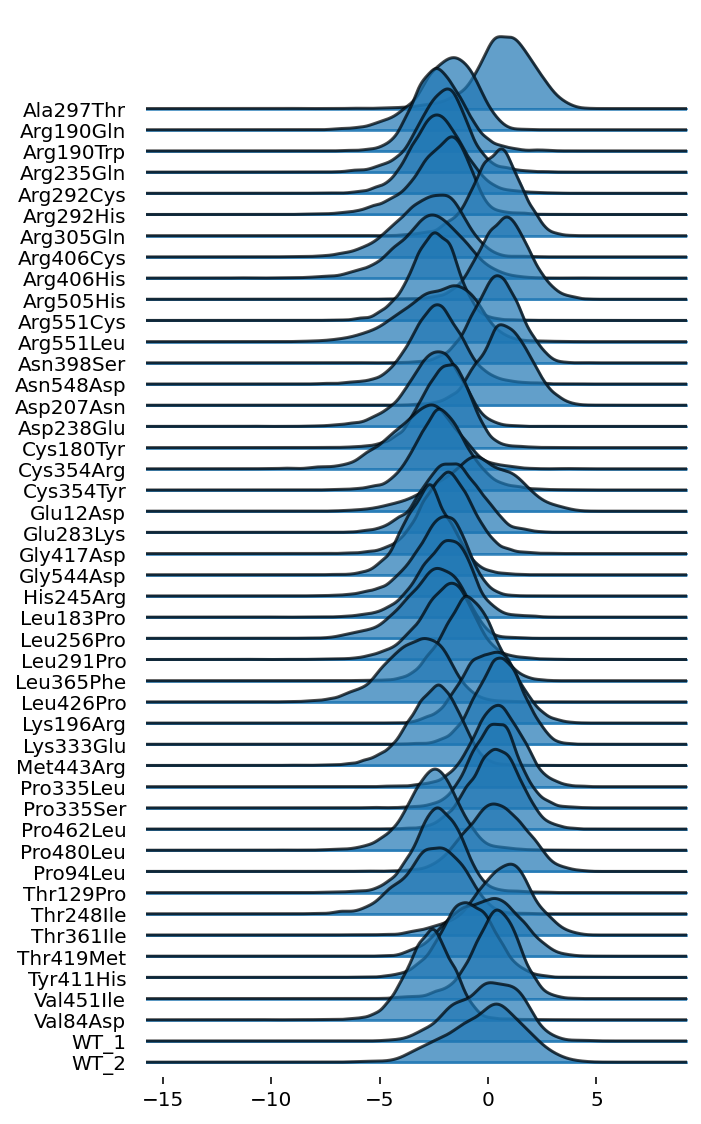

In [62]:
joyplot(reduced_df[reduced_df.symbol == 'STXBP1'], by='aa_change', column=['GFP_mCherry_ratio'],figsize=(5,8), alpha=0.7);
#plt.xlabel('GFP_mCherry_ratio');
#plt.title("Ridgeline Plot, multiple groups");

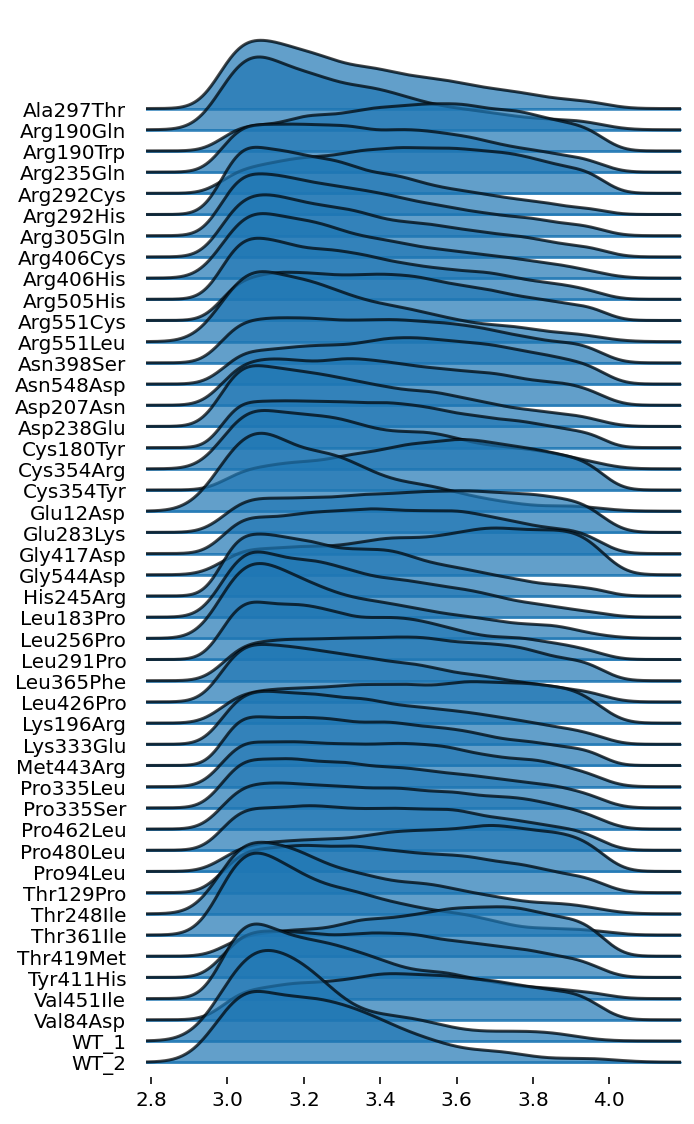

In [63]:
joyplot(reduced_df[reduced_df.symbol == 'STXBP1'], by='aa_change', column=['mCherry_log10'],figsize=(5,8), alpha=0.7);

In [64]:
reduced_df.query("symbol == 'STXBP1' and aa_change.str.contains('WT')").aa_change.value_counts()

WT_1    320
WT_2    320
Name: aa_change, dtype: int64

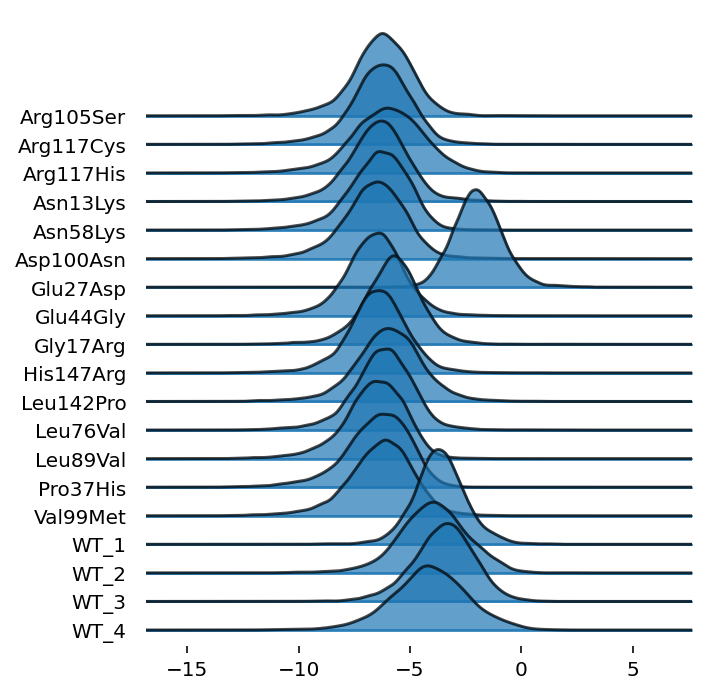

In [65]:
joyplot(pDEST_DUAL_expr_df[pDEST_DUAL_expr_df.symbol == 'HBD'], by='aa_change', column=['GFP_mCherry_ratio'],figsize=(5,5), alpha=0.7);
#plt.xlabel('GFP_mCherry_ratio');
#plt.title("Ridgeline Plot, multiple groups");
plt.show()

In [66]:
joyplot(HBD_df, by='aa_change', column=['GFP_mCherry_ratio'],figsize=(5,5), alpha=0.7);
#plt.xlabel('GFP_mCherry_ratio');
#plt.title("Ridgeline Plot, multiple groups");
plt.show()

NameError: name 'HBD_df' is not defined

In [ ]:
HBD_df = pDEST_DUAL_df[pDEST_DUAL_df.symbol == 'HBD'].copy()

#n_cell_d = dict(HBD_df.aa_change.value_counts())
#HBD_df['n_cells'] = HBD_df.aa_change.map(n_cell_d)

HBD_df['expr_cat'] = HBD_df.mCherry_log10.apply(lambda x: f'{str(int(x))}-{str(int(x+1))}')
HBD_df['aa_change_expr_cat'] = list(zip(HBD_df.aa_change, HBD_df.expr_cat))

n_cell_d = dict(HBD_df.aa_change_expr_cat.value_counts())
HBD_df['n_cells'] = HBD_df.aa_change_expr_cat.map(n_cell_d)
HBD_df['aa_change_expr_cat'] = list(zip(HBD_df.aa_change, HBD_df.expr_cat, HBD_df.n_cells))

HBD_df.head()

In [ ]:
joyplot(HBD_df[HBD_df.aa_change.str.contains('WT')], by='aa_change_expr_cat', column=['mCherry_log10'],figsize=(5,5), alpha=0.7);
#plt.xlabel('GFP_mCherry_ratio');
#plt.title("Ridgeline Plot, multiple groups");
plt.show()

In [ ]:
joyplot(HBD_df[HBD_df.aa_change.str.contains('WT')], by='aa_change_expr_cat', column=['mCherry_log10'],figsize=(5,5), alpha=0.7);
#plt.xlabel('GFP_mCherry_ratio');
#plt.title("Ridgeline Plot, multiple groups");
plt.show()

In [ ]:
joyplot(HBD_df[HBD_df.aa_change.str.contains('WT')], by='aa_change_expr_cat', column=['GFP_mCherry_ratio'],figsize=(5,5), alpha=0.7);
#plt.xlabel('GFP_mCherry_ratio');
#plt.title("Ridgeline Plot, multiple groups");
plt.show()

In [ ]:
joyplot(HBD_df[HBD_df.aa_change.str.contains('WT')], by='aa_change_expr_cat', column=['GFP_mCherry_ratio'],figsize=(5,5), alpha=0.7);
#plt.xlabel('GFP_mCherry_ratio');
#plt.title("Ridgeline Plot, multiple groups");
plt.show()

In [ ]:
joyplot(HBD_df, by='aa_change_expr_cat', column=['mCherry_log10'],figsize=(5,15), alpha=0.7);
#plt.xlabel('GFP_mCherry_ratio');
#plt.title("Ridgeline Plot, multiple groups");
plt.show()

In [ ]:
joyplot(HBD_df, by='aa_change_expr_cat', column=['mCherry_log10'],figsize=(5,35), alpha=0.7);
#plt.xlabel('GFP_mCherry_ratio');
#plt.title("Ridgeline Plot, multiple groups");
plt.show()

In [ ]:
joyplot(HBD_df, by='aa_change_expr_cat', column=['GFP_mCherry_ratio'],figsize=(5,15), alpha=0.7);
#plt.xlabel('GFP_mCherry_ratio');
#plt.title("Ridgeline Plot, multiple groups");
plt.show()

In [ ]:
joyplot(HBD_df, by='aa_change_expr_cat', column=['GFP_mCherry_ratio'],figsize=(5,35), alpha=0.7);
#plt.xlabel('GFP_mCherry_ratio');
#plt.title("Ridgeline Plot, multiple groups");
plt.show()

In [ ]:
HBD_df.mCherry_log10.plot.hist()

In [ ]:
joyplot(pDEST_DUAL_df[pDEST_DUAL_df.symbol == 'HBD'], by='aa_change', column='mCherry_log10', colormap=sns.color_palette("crest", as_cmap=True),figsize=(3,6));
plt.xlabel('mCherry_log10');
plt.title("Ridgeline Plot, multiple groups");

In [ ]:
joyplot(pDEST_DUAL_df[pDEST_DUAL_df.symbol == 'HBD'], by='aa_change', column='GFP_log10', colormap=sns.color_palette("crest", as_cmap=True),figsize=(3,6));
plt.xlabel('GFP_log10');
plt.title("Ridgeline Plot, multiple groups");

In [ ]:
joyplot(pDEST_DUAL_df[pDEST_DUAL_df.symbol == 'HBD'], by='aa_change', column='GFP_mCherry_ratio', colormap=sns.color_palette("crest", as_cmap=True),figsize=(3,6));
plt.xlabel('GFP_mCherry_ratio');
plt.title("Ridgeline Plot, multiple groups");

---------------------------------

In [ ]:
df['GFP_log'] = df.GFP.apply(np.log10)
df['mCherry_log'] = df.mCherry.apply(np.log10)
df['expr_cat'] = df.mCherry_log.apply(lambda x: f'{str(int(x))}-{str(int(x+1))}')

plt.figure(figsize=(5,5))
sns.scatterplot(data=df, x='GFP_log', y='mCherry_log', alpha=0.3)

print(pearsonr(df.GFP_log, df.mCherry_log))
print(spearmanr(df.GFP_log, df.mCherry_log))

plt.show();

In [ ]:
sns.histplot(data=df,x='mCherry_log', kde=True)

In [ ]:
sns.kdeplot(data=df,x='mCherry_log', hue='expr_cat', common_norm=False);

In [ ]:
sns.kdeplot(data=df,x='GFP_log', hue='expr_cat', common_norm=False);

In [ ]:
sns.histplot(data=df,x='mCherry_log', hue='expr_cat', stat='density', alpha=0.5);

In [ ]:
sns.histplot(data=df,x='GFP_log', hue='expr_cat', stat='density', alpha=0.5, common_norm=False);

In [ ]:
sns.kdeplot(data=df[(3.45 < df.mCherry_log) &(df.mCherry_log < 3.55)],x='GFP_log', hue='expr_cat');

In [ ]:
pdest_layout_df = pd.read_csv('../experiment_designs/20220803_pDEST_DUAL_batch5/VUS_PDEST_dual_experiment_batch5_table_annotated.csv', index_col=0)
pdest_layout_df['pDEST_results'] = [results_d[pla,well] if (pla,well) in results_d else np.nan for pla,well in zip(pdest_layout_df.dest_pla_id, pdest_layout_df.dest_well)]
pdest_layout_df['n_cells'] = pdest_layout_df.pDEST_results.apply(len)

pdest_layout_df.head()

In [ ]:
pdest_layout_df.n_cells.sum()